# Control de un sistema térmico MIMO 2×2 mediante desacoplo estático y control PI
**Sistemas de Control – 2026-2 – Universidad de Antioquia**  ·  Profesor: Hernán Felipe García Arias

**Integrantes:** Andrés Ignacio Ojeda (1233191481) y Juan Manuel Álvarez (1059239415)    

---
Cuaderno **reproducible** del miniproyecto. Se ejecuta completo con *Run All* desde la carpeta `entrega/` y reconstruye todas las tablas y figuras a partir de los datos crudos de `datos/`.

| Sección | Fase del enunciado |
|---|---|
| 0 | Configuración |
| 1 | Fase 0 – Preparación, protocolo y seguridad |
| 2 | Fase 1 – Identificación experimental de los cuatro canales |
| 3 | Fase 2 – Modelo multivariable y diagnóstico de interacción |
| 4 | Fase 3 – Diseño y verificación del desacoplador estático |
| 5 | Fase 4 – Diseño de los controladores PI |
| 6 | Fase 5 – Pruebas comparativas A/B (simulación y equipo) |
| 7 | Fase 6 – Cuantificación del desempeño |
| 8 | Preguntas orientadoras para la discusión |
| 9 | Limitaciones y conclusiones |
| 10 | Diccionario de variables, archivos y referencias |

Las partes que dependen de los ensayos en lazo cerrado sobre el equipo se completan solas cuando existen los archivos en `datos/lazo_cerrado/` (generados por el código de la sección 6.0). Los textos que todavía dependen de esos ensayos están marcados con **[pendiente lab]**.

**Convención:** $G_{ij}$ = efecto de la entrada $Q_j$ sobre la salida $T_i$ (fila = salida, columna = entrada).

## 0. Configuración

In [151]:
import os, sys, glob, re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.signal import medfilt
from IPython.display import display, Markdown, Math, Image
sys.path.insert(0, 'codigo')
from mimo_control import PlantFOPDT, simular_lazo_cerrado, simular_lazo_abierto, indicadores, Vigilante

np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

# ---------------- Rutas ----------------
DIR_ID = 'datos/identificacion'                     # ensayos de identificación válidos (E1, E2)
DIR_LC = 'datos/lazo_cerrado'                       # ensayos A/B en el equipo (sección 6.0)
DIR_QOP = 'datos/punto_operacion'                   # aproximación a 55 °C del 23-oct usada para Q_OP
DIR_FIG, DIR_TAB = 'figuras', 'tablas'
for d in (DIR_FIG, DIR_TAB, DIR_LC): os.makedirs(d, exist_ok=True)

ENSAYOS = {   # identificación (si se repite en el laboratorio, cambiar aquí los archivos)
    'E1': 'ensayo1_Q1_principal_20261023_130503.csv',   # Q1: 0 → 5 → 12 %, luego Q2 = 8 %
    'E2': 'ensayo1_Q2_principal.csv',                   # Q2: 0 → 5 → 12 %, luego Q1 = 8 %
}

# ---------------- Parámetros de análisis ----------------
DESPIKE_N = 5          # muestras del filtro de mediana antes de ajustar (el CSV conserva los datos crudos)
STEADY_WIN, STEADY_SLOPE = 120., 0.003   # s y °C/s: criterio de tramo estacionario

# ---------------- Punto de operación, límites y diseño ----------------
T_OP = np.array([55., 55.])   # °C: punto de operación usado en los ensayos en lazo cerrado
QMIN, QMAX = 0., 30.          # %: saturación (ver cambios del 27 y 28-oct en la sección 1.2)
T_MAX = 110.                  # °C: corte de seguridad del equipo
Ts, T_STEP, T_POST = 1.0, 60., 1200.   # s: muestreo, instante del escalón en simulación, registro post-escalón
LAMBDA_FACTOR = 1.5           # IMC: λ = 1.5·τ (0.8·τ hasta el 27-oct, ver sección 1.2)
SCEN = {'S1': np.array([5., 0.]), 'S2': np.array([0., 5.]), 'S3': np.array([5., 3.])}

def guardar_fig(fig, nombre): fig.savefig(os.path.join(DIR_FIG, nombre), dpi=130, bbox_inches='tight')
def guardar_tabla(df, nombre): df.to_csv(os.path.join(DIR_TAB, nombre))
def leer_meta(path):
    for enc in ('utf-8', 'latin-1'):
        try:
            with open(path, encoding=enc) as f:
                return {k.strip(): v.strip() for k, v in (l.split(':', 1) for l in f.read().splitlines() if ':' in l)}
        except UnicodeDecodeError:
            pass
    return {}

## 1. Fase 0 – Preparación, protocolo y seguridad

### 1.1 Montaje
```
             ┌──────────────── Placa TCLab (Arduino Mega 2560, firmware 1.0.1) ────────────────┐
  PC (Python)│   Q1 ──► Calentador 1 (transistor + resistencia)  ··· acople térmico ···  Calentador 2 ◄── Q2 │
   USB/COM3  │   T1 ◄── Sensor 1 (junto al calentador 1)                      Sensor 2 ◄── T2        │
             └─────────────────────────────────────────────────────────────────────────────────┘
```
- **Variables manipuladas:** $Q_1, Q_2$ = orden de potencia de cada calentador en % (PWM), enviadas con la librería `tclab`.
- **Variables medidas:** $T_1, T_2$ en °C, leídas con el mismo reloj que las potencias.
- **Periodo de muestreo:** $T_s = 1$ s (identificación y lazo cerrado).
- **Cambio de hardware:** los cables de los calentadores se reemplazaron por unos más gruesos (cambio **validado por el laboratorio**). Desde entonces la ganancia es ≈ 5 veces la de un TCLab típico (≈ 2.5 °C/% contra 0.4–0.6 °C/%), por eso se usaron potencias bajas.

### 1.2 Límites de operación y parada segura
| Ítem | Identificación | Lazo cerrado |
|---|---|---|
| Potencia | 0–12 % entrada principal, 8 % entrada cruzada | 0–30 % (saturación del controlador) |
| Temperatura máxima | corte por mediana de 5 lecturas ≥ `T_MAX` | `T_MAX = 110 °C`, mediana de 5 lecturas |
| Duración | 31 min por ensayo | aproximación ≤ 25 min + 20 min de respuesta |
| Parada segura | `Q1 = Q2 = 0` en un bloque `finally` (fin normal, error, Ctrl+C o ventana cerrada) | igual, más las protecciones de la clase `Vigilante` |

**Protecciones adicionales en lazo cerrado** (clase `Vigilante`, `codigo/mimo_control.py`), agregadas después de las fallas de hardware del 23-oct:
1. **Calentador que no responde:** $Q_i \ge 15\,\%$ durante 120 s con error > 15 °C y $T_i$ sube menos de 3 °C → se detiene el ensayo.
2. **Lectura físicamente imposible:** la temperatura cae más rápido que el enfriamiento libre $(T_i - 25)/200 + 0.05$ °C/s, o sube más de 1 °C/s → se detiene el ensayo.

**Intentos fallidos** (no se usan en este cuaderno; sus gráficas están en la carpeta `anexos/`, nombradas por fecha y hora, con el índice `A00_indice_anexos.csv`):
| Fecha | Intentos | Qué pasó | Qué se cambió |
|---|---|---|---|
| 22-oct (15:28) y 23-oct (12:00–13:02) | 7 de identificación | 2 con el perfil original (15 → 50 %), que calentaba demasiado rápido (T1 a 56 °C en menos de 5 min); 5 con el perfil final, detenidos a mano antes de completar el perfil | escalones de 5 y 12 % y cruzado de 8 % (E1 y E2 válidos: 23-oct, 13:05–14:24) |
| 23-oct (tarde, hasta las 15:54) | 3 de S1-A | calentadores que no calentaban y lectura imposible del sensor 2 | protecciones `Vigilante` |
| 27-oct (15:23–18:34) | 11 de S1-A | cables sueltos (lecturas de hasta 426 °C), calentadores sin respuesta y, con una fuente de reemplazo, lazos oscilando (±7 °C, periodo ≈ 10 min) | cables fijos, fuente original, PI más suaves (λ = 1.5·τ, antes 0.8·τ), saturación 30 % y consigna en rampa |

Los cuatro ensayos A/B válidos se tomaron el **28-oct** (12:35–16:16) con la configuración final.

### 1.3 Secuencia de pruebas
| Orden | Prueba | Objetivo |
|---|---|---|
| 1 | E1: escalones en $Q_1$ (0 → 5 → 12 %), luego $Q_2 = 8$ % | $G_{11}, G_{21}$ (y $G_{12}, G_{22}$ por superposición) |
| 2 | E2: escalones en $Q_2$ (0 → 5 → 12 %), luego $Q_1 = 8$ % | $G_{12}, G_{22}$ (y $G_{11}, G_{21}$ por superposición) |
| 3 | S1-A, S1-B, S2-A, S2-B | comparación con y sin desacoplador |

Cada ensayo de identificación arranca con el equipo frío (≈ ambiente) y una línea base de 60 s con ambas potencias en 0 %, para separar la interacción de cambios espontáneos de temperatura.

### 1.4 Código de adquisición en el equipo y diagnóstico
Las celdas de equipo (esta, la 2.0 y la 6.0) contienen el código con el que se tomaron los datos en el TCLab. Con `EJECUTAR_EQUIPO = False` (valor por defecto) solo definen funciones: *Run All* no se conecta al equipo y todo el análisis se hace con los datos guardados en `datos/`. Para repetir un ensayo: conectar el TCLab (COM3), poner `EJECUTAR_EQUIPO = True`, esperar a que el equipo esté frío, ejecutar **una sola** celda de ensayo y supervisarlo; la gráfica en vivo se abre en una ventana aparte (cerrarla termina el ensayo). Cada ensayo se guarda con fecha y hora, sin sobrescribir los anteriores.

In [152]:
# Código de adquisición en el equipo (TCLab): con EJECUTAR_EQUIPO = False solo se definen funciones
import csv, time, datetime
from mimo_control import PI2, paso_control
try:
    import tclab
except ImportError:
    tclab = None                  # el análisis no lo necesita

EJECUTAR_EQUIPO = False           # True solo con el TCLab conectado y supervisado

# ---------------- Seguridad y protocolo de los ensayos (T_MAX, QMIN, QMAX en la sección 0) ----------------
T_MAX_N = 5                       # corte por la mediana de las últimas 5 lecturas
TS, FILT_N = Ts, 5                # s; mediana de 5 muestras para la medición del lazo
T_APPROACH_MIN, T_APPROACH_MAX = 300.0, 1500.0
STEADY_TOL, STEADY_S, STEADY_AVG_S = 0.7, 120.0, 30.0
RAMPA_C_S = 0.05                  # °C/s: rampa de la consigna en la aproximación (3 °C/min)
DIR_DIAG, REGISTRO = 'datos/diagnostico', 'datos/registro_laboratorio.csv'

def en_ventana(fn, *args):
    # Gráfica en vivo en una ventana aparte (backend tk) y luego vuelta a las figuras en línea
    ip = get_ipython(); ip.run_line_magic('matplotlib', 'tk')
    try: return fn(*args)
    finally: ip.run_line_magic('matplotlib', 'inline')

def nombre_libre(base, ext):
    # Nombre con fecha y hora: nunca sobrescribe un ensayo anterior
    return f"{base}_{datetime.datetime.now():%Y%m%d_%H%M%S}{ext}"

def registrar(paso, archivo, resultado, motivo, notas=''):
    nuevo = not os.path.exists(REGISTRO)
    with open(REGISTRO, 'a', newline='', encoding='utf-8') as f:
        w = csv.writer(f)
        if nuevo: w.writerow(['fecha', 'paso', 'archivo', 'resultado', 'motivo', 'notas'])
        w.writerow([f'{datetime.datetime.now():%Y-%m-%d %H:%M:%S}', paso, archivo, resultado, motivo, notas])

class Ventana:
    # Gráfica en vivo: temperaturas (y consignas) arriba, potencias abajo
    def __init__(self, titulo, con_consigna=False):
        plt.ion()
        self.fig, (self.aT, self.aQ) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
        self.l = {k: self.aT.plot([], [], color=c, lw=1, label=k)[0] for k, c in (('T1', 'tab:blue'), ('T2', 'tab:red'))}
        if con_consigna:
            self.l.update({k: self.aT.plot([], [], '--', color=c, lw=1, label=k)[0] for k, c in (('r1', 'navy'), ('r2', 'darkred'))})
        self.l.update({k: self.aQ.plot([], [], color=c, label=k)[0] for k, c in (('Q1', 'tab:blue'), ('Q2', 'tab:red'))})
        self.aT.set_title(titulo); self.aT.set_ylabel('Temperatura [°C]'); self.aQ.set_ylabel('Potencia [%]'); self.aQ.set_xlabel('Tiempo [s]')
        for a in (self.aT, self.aQ): a.grid(alpha=.3); a.legend(loc='upper left')
        self.aQ.set_ylim(-2, QMAX + 5); self.fig.tight_layout()
    def abierta(self): return plt.fignum_exists(self.fig.number)
    def actualizar(self, t, datos, xmax=None):
        for k, y in datos.items(): self.l[k].set_data(t, y)
        if xmax: self.aT.set_xlim(0, xmax)
        self.aT.relim(); self.aT.autoscale_view(scalex=False)
    def marca(self, x):
        for a in (self.aT, self.aQ): a.axvline(x, color='k', ls='--', lw=1)
    def guardar(self, path):
        try: self.fig.savefig(path, dpi=130)
        except Exception: pass

def apagar(lab):
    try:
        lab.Q1(0); lab.Q2(0)
    except Exception as e:
        print(f'[ATENCIÓN] no se pudo apagar el TCLab ({e}). Desconéctalo de la alimentación.')

def correr_lazo_abierto(nombre, duracion, perfil, titulo, e_vigilante=None):
    # Ensayo en lazo abierto con perfil(t) -> (Q1, Q2). Devuelve DataFrame y motivo de fin.
    path = nombre_libre(os.path.join(DIR_DIAG, nombre), '.csv')
    v = Ventana(titulo); vg = Vigilante(); filas = []; motivo = 'completo'
    with tclab.TCLab() as lab:
        apagar(lab); t0 = time.perf_counter(); k = 0
        try:
            while True:
                plt.pause(max(k*TS - (time.perf_counter() - t0), 0.001)); now = time.perf_counter() - t0
                if not v.abierta(): motivo = 'ventana cerrada por el usuario'; break
                if now >= duracion: break
                q1, q2 = perfil(now); lab.Q1(q1); lab.Q2(q2)
                a, b = lab.T1, lab.T2; filas.append((now, q1, q2, a, b))
                T1s, T2s = [f[3] for f in filas], [f[4] for f in filas]
                if max(np.median(T1s[-T_MAX_N:]), np.median(T2s[-T_MAX_N:])) >= T_MAX:
                    motivo = f'LÍMITE DE TEMPERATURA ({T_MAX:.0f} °C)'; break
                e = e_vigilante(q1, q2) if e_vigilante else [0., 0.]
                alarma = vg.revisar(now, [a, b], [q1, q2], e)
                if alarma: motivo = f'ANOMALÍA: {alarma}'; break
                tt = [f[0] for f in filas]
                v.actualizar(tt, {'T1': T1s, 'T2': T2s, 'Q1': [f[1] for f in filas], 'Q2': [f[2] for f in filas]}, duracion)
                if k % 30 == 0: print(f'[{now:6.0f} s] T1={a:6.2f} T2={b:6.2f} °C  Q1={q1:4.1f} Q2={q2:4.1f} %')
                k += 1
        except KeyboardInterrupt:
            motivo = 'abortado por el usuario'
        except Exception as ex:
            motivo = f'ERROR ({type(ex).__name__}: {ex})'
        finally:
            apagar(lab)
    d = pd.DataFrame(filas, columns=['tiempo_s', 'Q1_pct', 'Q2_pct', 'T1_C', 'T2_C'])
    d.to_csv(path, index=False); v.guardar(path.replace('.csv', '.png'))
    print(f'Fin: {motivo}. Calentadores apagados. Datos: {path}')
    return d, motivo, path

def diagnostico_sensores():
    # 10 min con los calentadores apagados (equipo frío)
    d1, motivo1, path1 = correr_lazo_abierto('diag_sensores', 600, lambda t: (0.0, 0.0), 'Diagnóstico de sensores (Q1 = Q2 = 0 %)')
    med = d1[['T1_C', 'T2_C']].rolling(5, center=True, min_periods=1).median()
    saltos = (med.diff().abs() > 1).sum()
    ruido = (d1[['T1_C', 'T2_C']] - med).std()
    dif = (med['T1_C'] - med['T2_C']).tail(120).mean()
    frio = d1[['T1_C', 'T2_C']].head(10).median().max() < 35
    apto1 = motivo1 == 'completo' and saltos.max() <= 2 and ruido.max() < 1.0 and (not frio or abs(dif) < 2)
    RES1 = pd.DataFrame({'saltos > 1 °C': saltos.values, 'ruido std [°C]': ruido.values}, index=['T1', 'T2'])
    display(RES1.round(3))
    print(f'T1 − T2 (últimos 120 s) = {dif:+.2f} °C {"(equipo frío)" if frio else "(equipo no estaba frío: dato informativo)"}')
    print('VEREDICTO:', 'APTO' if apto1 else 'NO APTO – revisar sensores/cables antes de seguir')
    registrar('1 diagnóstico sensores', path1, 'APTO' if apto1 else 'NO APTO', motivo1,
              f'saltos={saltos.tolist()} ruido={ruido.round(2).tolist()} T1-T2={dif:+.2f}')

def diagnostico_calentadores():
    # Q1 = 15 % durante 150 s y luego Q2 = 15 % durante 150 s
    Q_DIAG, TRAMO = 15.0, 150.0
    perfil2 = lambda t: (Q_DIAG, 0.0) if t < TRAMO else (0.0, Q_DIAG)
    e_diag = lambda q1, q2: [10.0 if q1 > 0 else 0.0, 10.0 if q2 > 0 else 0.0]
    d2, motivo2, path2 = correr_lazo_abierto('diag_calentadores', 2*TRAMO, perfil2,
                                             f'Diagnóstico de calentadores: Q1 = {Q_DIAG:.0f} % y luego Q2 = {Q_DIAG:.0f} %', e_diag)
    m = d2[['T1_C', 'T2_C']].rolling(5, center=True, min_periods=1).median(); t = d2['tiempo_s']
    def valor(col, t_ref): return m.loc[(t - t_ref).abs().idxmin(), col]
    dT1 = valor('T1_C', TRAMO - 3) - valor('T1_C', 3)
    dT2 = valor('T2_C', 2*TRAMO - 3) - valor('T2_C', TRAMO + 3)
    apto2 = motivo2 == 'completo' and dT1 >= 5 and dT2 >= 5
    print(f'ΔT1 con Q1 = {Q_DIAG:.0f} %: {dT1:+.2f} °C   ΔT2 con Q2 = {Q_DIAG:.0f} %: {dT2:+.2f} °C')
    print('VEREDICTO:', 'APTO' if apto2 else 'NO APTO – revisar calentadores, cables y fuente antes de seguir')
    registrar('2 diagnóstico calentadores', path2, 'APTO' if apto2 else 'NO APTO', motivo2, f'dT1={dT1:+.2f} dT2={dT2:+.2f}')

**Prueba de sensores (27-oct, 17:29).** Después de las fallas de cables se revisó el equipo en tres partes: calentadores apagados, $Q_2$ alternando y ambas potencias fijas en 10 %. Los dos sensores responden, la corriente de los calentadores no desplaza la lectura (se descarta un problema de tierra) y $T_2$ es el sensor más ruidoso, lo que explica el ruido de $T_2$ en los ensayos en lazo cerrado.

,parte,sensor,mín [°C],máx [°C],ruido std [°C],saltos >2 °C entre muestras,saltos >5 °C
0,A_apagados,T1,27.52,34.46,0.80,18,0
1,A_apagados,T2,23.61,34.36,0.94,22,2
2,B_alterna_Q2,T1,27.22,32.16,0.78,7,0
3,B_alterna_Q2,T2,23.90,34.65,1.66,15,4
4,C_fijo_10,T1,28.79,63.15,0.82,37,1
5,C_fijo_10,T2,29.08,53.57,1.02,57,7


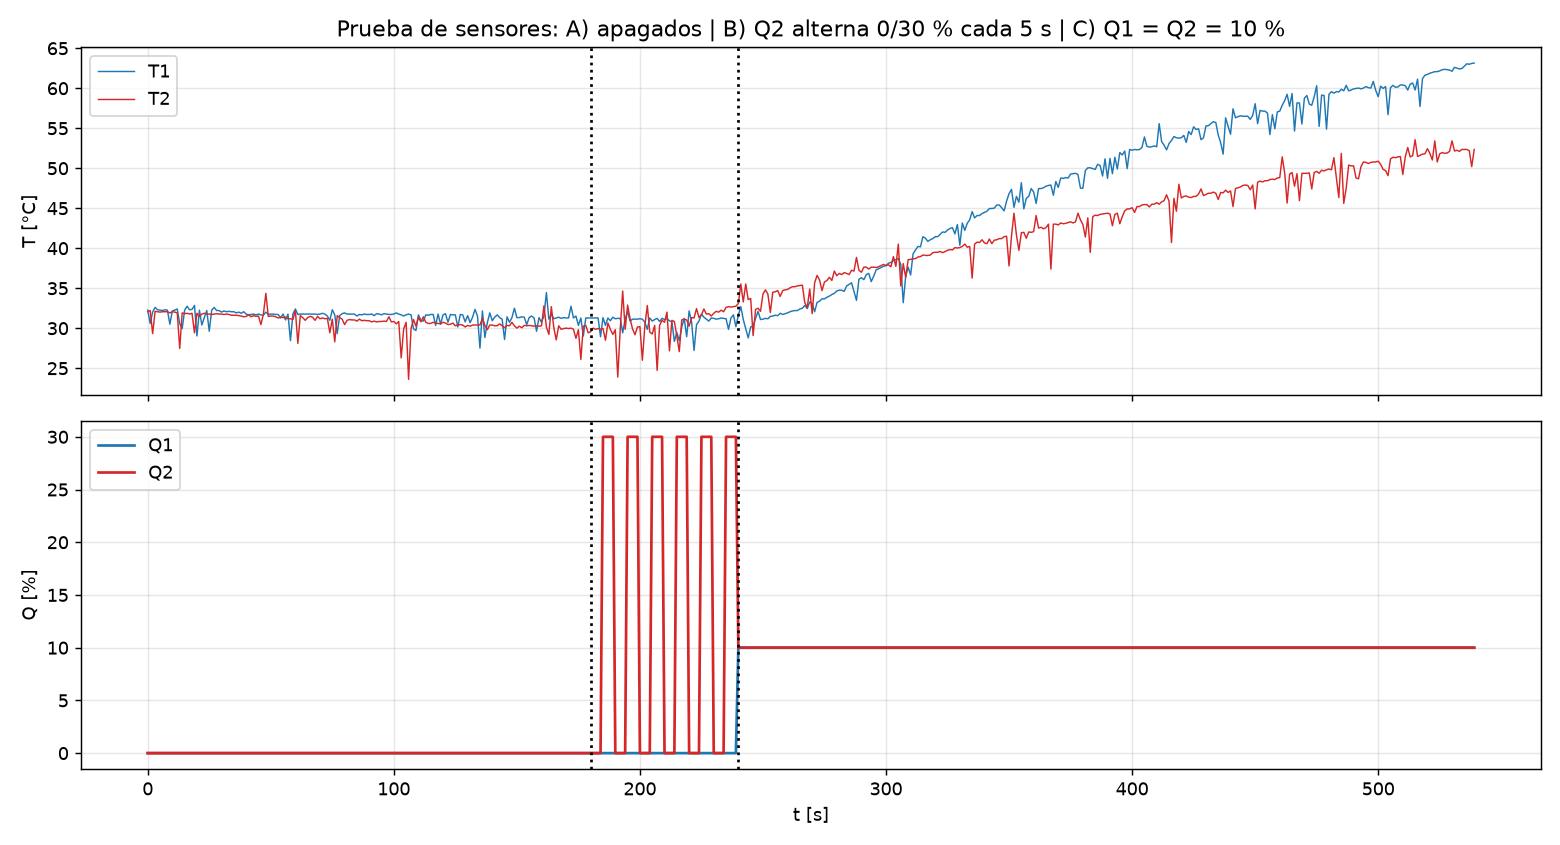

In [153]:
DIAGNOSTICO = False   # True para revisar sensores (10 min, equipo frío) y calentadores (5 min) antes de los ensayos
if EJECUTAR_EQUIPO and DIAGNOSTICO:
    en_ventana(diagnostico_sensores); en_ventana(diagnostico_calentadores)

# Prueba de sensores registrada el 27-oct
diag = sorted(glob.glob(os.path.join(DIR_DIAG, 'prueba_sensores_*_resumen.csv')))
if diag:
    display(pd.read_csv(diag[-1]).round(2))
    display(Image(diag[-1].replace('_resumen.csv', '.png'), width=850))

## 2. Fase 1 – Identificación experimental de los cuatro canales

**Cambio documentado respecto del enunciado:** el valor nominal propuesto (escalón 0 → 60 %) no es seguro en este equipo: con $K \approx 2.5$–4 °C/% llevaría la temperatura muy por encima de 100 °C. Se usaron **dos escalones de la entrada principal (5 % y 12 %)** y luego un **escalón cruzado de 8 %** en la otra entrada, con tramos de 10 min. Así, cada canal se identifica en los dos ensayos (una vez como canal principal y otra por superposición).

### 2.0 Adquisición en el equipo
E1 y E2 se tomaron con `codigo/adquisicion_identificacion.py`. La celda siguiente repite un ensayo con el mismo programa y perfil (solo si el equipo cambió, p. ej. después de una reparación: el modelo, $D_0$ y los PI dejarían de valer). Dejar enfriar a ambiente antes de cada ensayo y, después, cambiar `ENSAYOS` en la sección 0 por los archivos nuevos.

In [154]:
REIDENTIFICAR = False      # poner True solo si hace falta
HEATER_REID = 1            # 1 = ensayo E1 (Q1 principal); luego 2 = ensayo E2 (Q2 principal), con el equipo frío

if EJECUTAR_EQUIPO and REIDENTIFICAR:
    import importlib.util
    spec = importlib.util.spec_from_file_location('adq', 'codigo/adquisicion_identificacion.py')
    adq = importlib.util.module_from_spec(spec); spec.loader.exec_module(adq)
    adq.HEATER, adq.OTHER = HEATER_REID, 2 if HEATER_REID == 1 else 1
    adq.FILENAME = os.path.join(DIR_ID, f'reid_Q{HEATER_REID}_principal.csv')
    adq.T_MAX = T_MAX
    adq.TRAMOS = adq.construir_perfil(); adq.DURACION_S = adq.TRAMOS[-1][1]
    adq.main()
    registrar(f'3 re-identificación Q{HEATER_REID}', adq.FILENAME, 'ver meta', '')
else:
    print('Re-identificación omitida: se usan E1 y E2 guardados en datos/identificacion/.')

Re-identificación omitida: se usan E1 y E2 guardados en datos/identificacion/.


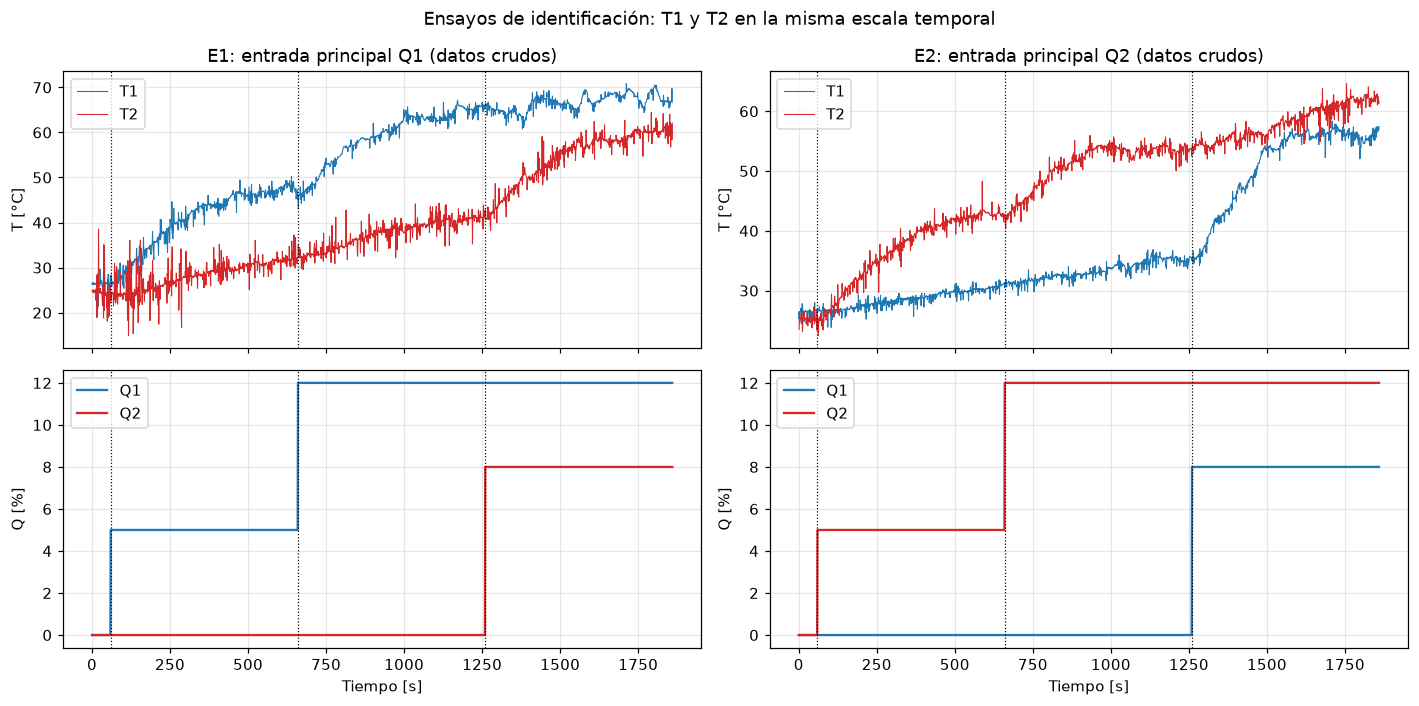

In [155]:
DATOS = {k: pd.read_csv(os.path.join(DIR_ID, f)) for k, f in ENSAYOS.items()}

def pasos(d, j):
    q, t = d[f'Q{j+1}_pct'].values, d['tiempo_s'].values
    idx = np.nonzero(np.diff(q))[0] + 1
    return [(t[i], q[i] - q[i-1]) for i in idx]
PASOS = {k: [pasos(d, 0), pasos(d, 1)] for k, d in DATOS.items()}
PRINC = {k: min((j for j in range(2) if p[j]), key=lambda j: p[j][0][0]) for k, p in PASOS.items()}
T_PASOS = {k: sorted(ts for p in PASOS[k] for ts, _ in p) for k in DATOS}

fig, ax = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
for c, (k, d) in enumerate(DATOS.items()):
    t = d['tiempo_s']
    ax[0, c].plot(t, d['T1_C'], lw=.7, label='T1'); ax[0, c].plot(t, d['T2_C'], lw=.7, color='C3', label='T2')
    ax[1, c].plot(t, d['Q1_pct'], label='Q1'); ax[1, c].plot(t, d['Q2_pct'], color='C3', label='Q2')
    ax[0, c].set_title(f"{k}: entrada principal Q{PRINC[k]+1} (datos crudos)")
    ax[0, c].set_ylabel('T [°C]'); ax[1, c].set_ylabel('Q [%]'); ax[1, c].set_xlabel('Tiempo [s]')
    for a in ax[:, c]:
        for ts in T_PASOS[k]: a.axvline(ts, color='k', ls=':', lw=.8)
        a.legend(loc='upper left')
fig.suptitle('Ensayos de identificación: T1 y T2 en la misma escala temporal'); fig.tight_layout()
guardar_fig(fig, 'F1_datos_crudos_identificacion.png'); plt.show()

### 2.1 Calidad de los datos

In [156]:
filas_r, filas_t = [], []
for k, d in DATOS.items():
    for col in ('T1_C', 'T2_C'):
        y = d[col].values; res = y - medfilt(y, DESPIKE_N)
        filas_r.append({'ensayo': k, 'sensor': col[:2], 'T máx [°C]': y.max(), 'ruido std [°C]': res.std(),
                        'picos > 2 °C': int((np.abs(res) > 2).sum())})
    for fase, g in d.groupby('fase', sort=False):
        fila = {'ensayo': k, 'tramo': fase, 'Q1 [%]': g['Q1_pct'].iloc[-1], 'Q2 [%]': g['Q2_pct'].iloc[-1]}
        ult = g[g['tiempo_s'] >= g['tiempo_s'].iloc[-1] - STEADY_WIN]
        for col in ('T1_C', 'T2_C'):
            y = medfilt(ult[col].values, DESPIKE_N)
            fila[f'{col[:2]} final [°C]'] = np.median(y[-60:])
            fila[f'pendiente {col[:2]} [°C/s]'] = np.polyfit(ult['tiempo_s'], y, 1)[0]
        fila['estacionario'] = all(abs(fila[f'pendiente T{i} [°C/s]']) < STEADY_SLOPE for i in (1, 2))
        filas_t.append(fila)
RUIDO = pd.DataFrame(filas_r).set_index(['ensayo', 'sensor'])
TRAMOS = pd.DataFrame(filas_t).set_index(['ensayo', 'tramo'])
guardar_tabla(RUIDO, 'calidad_ruido.csv'); guardar_tabla(TRAMOS, 'calidad_tramos.csv')
display(RUIDO.round(2)); display(TRAMOS.round(4))
n_no = int((~TRAMOS.loc[TRAMOS.index.get_level_values(1) != 'base', 'estacionario']).sum())
display(Markdown(f"**Reconocimiento explícito:** {n_no} de {len(TRAMOS) - len(DATOS)} tramos con escalón **no alcanzaron "
                 "estado estacionario** en 10 min (pendiente final > 0.003 °C/s). Por eso no se usa solo el método de dos "
                 "puntos (que toma el valor final del tramo como estacionario) sino un ajuste por mínimos cuadrados con "
                 "superposición, que extrapola el valor final a partir de la forma de la curva."))

T máx [°C]  ruido std [°C]  picos > 2 °C
ensayo sensor                                          
E1     T1           70.82            0.78            81
       T2           64.42            1.60           239
E2     T1           58.36            0.49            15
       T2           64.61            0.74            73

Q1 [%]  Q2 [%]  T1 final [°C]  pendiente T1 [°C/s]  T2 final [°C]  pendiente T2 [°C/s]  estacionario
ensayo tramo                                                                                                            
E1     base            0.0     0.0        26.4420               0.0027        24.4870              -0.0198         False
       escalon1_Q1     5.0     0.0        47.9225               0.0110        31.6230               0.0116         False
       escalon2_Q1    12.0     0.0        65.2490               0.0160        41.1050               0.0146         False
       cruzado_Q2     12.0     8.0        66.9600              -0.0010        60.5815               0.0095         False
E2     base            0.0     0.0        26.4910              -0.0014        25.3180              -0.0032         False
       escalon1_Q2     0.0     5.0        30.5960               0.0087        42.6690               0.0050         False
       escalon2_Q2     0.0    12.0        35.0440              -0.0046        53.6170              -0.0022         False
       cruzado_Q1      8.0    12.0        55.6695               0.0016        62.0720               0.0072         False

**Reconocimiento explícito:** 6 de 6 tramos con escalón **no alcanzaron estado estacionario** en 10 min (pendiente final > 0.003 °C/s). Por eso no se usa solo el método de dos puntos (que toma el valor final del tramo como estacionario) sino un ajuste por mínimos cuadrados con superposición, que extrapola el valor final a partir de la forma de la curva.

### 2.2 Método 1: dos puntos (Smith, 28.3 % y 63.2 %), calculado por el programa de adquisición

In [157]:
DP = pd.concat([pd.read_csv(os.path.join(DIR_ID, f.replace('.csv', '_dos_puntos.csv'))).assign(ensayo=k)
                for k, f in ENSAYOS.items()])
cols = ['ensayo', 'tramo', 'canal', 'tipo', 'dQ_pct', 'dT_C', 'K_C_por_pct', 'theta_s', 'tau_s', 'nota']
guardar_tabla(DP[cols].set_index(['ensayo', 'tramo', 'canal']), 'identificacion_dos_puntos.csv')
display(DP[cols].round(3).set_index(['ensayo', 'tramo', 'canal']))

tipo  dQ_pct    dT_C  K_C_por_pct  theta_s    tau_s                                               nota
ensayo tramo       canal                                                                                                           
E1     escalon1_Q1 G11    directo     5.0  21.346        4.269   47.458  162.915  no estacionario al final del tramo (pendiente ...
                   G21    cruzado     5.0   7.354        1.471  104.594  206.898  no estacionario al final del tramo (pendiente ...
       escalon2_Q1 G11    directo     7.0  17.892        2.556   12.055  224.784  no estacionario al final del tramo (pendiente ...
                   G21    cruzado     7.0   9.228        1.318   72.425  178.430  no estacionario al final del tramo (pendiente ...
       cruzado_Q2  G12    cruzado     8.0   2.009        0.251  142.062   10.563  el tramo anterior no estaba estable (pendiente...
                   G22    directo     8.0  19.476        2.434   13.862  193.689  no estacionario al final del tramo (pendiente ...
E2     escalon1_Q2 G12    cruzado     5.0   4.188        0.838   76.419  288.462  no estacionario al final del tramo (pendiente ...
                   G22    directo     5.0  17.613        3.523   24.761  204.538  no estacionario al final del tramo (pendiente ...
       escalon2_Q2 G12    cruzado     7.0   4.313        0.616   13.452  318.066  no estacionario al final del tramo (pendiente ...
                   G22    directo     7.0  10.843        1.549   47.281   96.988  el tramo anterior no estaba estable (pendiente...
       cruzado_Q1  G11    directo     8.0  20.754        2.594   11.092  168.942  el tramo anterior no estaba estable (pendiente...
                   G21    cruzado     8.0   8.363        1.045   17.890  337.264  no estacionario al final del tramo (pendiente ...

### 2.3 Método 2: mínimos cuadrados con superposición sobre ambos ensayos (valores adoptados)
Cada salida se modela como la suma de las respuestas a **todos** los escalones de $Q_1$ y $Q_2$, ajustando los dos ensayos a la vez sobre los datos sin picos (mediana de 5 muestras):

$$T_i(t) = T_{i,0} + \sum_{\text{escalones}} K\,\Delta Q\left(1 - e^{-(t - t_s - \theta)/\tau}\right)\,\mathbb{1}(t \ge t_s + \theta)$$

- Parámetros por salida: $(K_{i1}, \tau_{i1}, \theta_{i1}, K_{i2}, \tau_{i2}, \theta_{i2})$ y, por ensayo, $T_{i,0}$.
- **No linealidad:** el primer escalón de cada ensayo (desde temperatura ambiente) tiene su propia ganancia $K_\text{arranque}$ (misma $\tau$ y $\theta$). Los $K_{ij}$ reportados corresponden así al **punto de operación** (≈ 40–65 °C) donde trabajan los controladores.
- Las σ provienen del jacobiano del ajuste (ruido blanco supuesto) y subestiman la incertidumbre real, sobre todo en los canales cruzados.

In [158]:
NOMBRES = list(DATOS)
def resp_fopdt(t, ts, dq, K_, tau, th):
    return K_*dq*(1 - np.exp(-np.clip(t - ts - th, 0, None)/tau))

def modelo_salida(p, k, t, usar_arranque=True):
    n = NOMBRES.index(k); K_arr, T0_ = p[6 + 2*n], p[7 + 2*n]
    y = np.full(len(t), T0_)
    for j in range(2):
        Kj, tau, th = p[3*j:3*j + 3]
        for m, (ts, dq) in enumerate(PASOS[k][j]):
            y = y + resp_fopdt(t, ts, dq, K_arr if (usar_arranque and j == PRINC[k] and m == 0) else Kj, tau, th)
    return y

K, TAU, THETA = np.zeros((2, 2)), np.zeros((2, 2)), np.zeros((2, 2))
SIG = np.zeros((2, 2, 3)); RMSE = np.zeros(2); P_FIT = {}
for i in range(2):
    med = {k: medfilt(d[f'T{i+1}_C'].values, DESPIKE_N) for k, d in DATOS.items()}
    def resid(p):
        return np.concatenate([modelo_salida(p, k, d['tiempo_s'].values) - med[k] for k, d in DATOS.items()])
    p0 = [2.5 if i == 0 else 0.8, 200, 20, 0.8 if i == 0 else 2.5, 200, 20] + [3., 25.]*len(NOMBRES)
    lb = [0, 10, 0]*2 + [0, 10]*len(NOMBRES); ub = [10, 3000, 300]*2 + [10, 45]*len(NOMBRES)
    mejor = None
    for th0 in (5, 30, 80):                       # varios arranques de θ (problema no convexo)
        p0[2] = p0[5] = th0
        s = least_squares(resid, p0, bounds=(lb, ub), x_scale='jac')
        if mejor is None or s.cost < mejor.cost: mejor = s
    p = P_FIT[i] = mejor.x
    cov = np.linalg.pinv(mejor.jac.T @ mejor.jac)*(mejor.fun @ mejor.fun)/(len(mejor.fun) - len(p))
    sd = np.sqrt(np.diag(cov)); RMSE[i] = np.sqrt(np.mean(mejor.fun**2))
    for j in range(2):
        K[i, j], TAU[i, j], THETA[i, j] = p[3*j:3*j + 3]; SIG[i, j] = sd[3*j:3*j + 3]

TAB_ID = pd.DataFrame([{'canal': f'G{i+1}{j+1}', 'K [°C/%]': K[i, j], 'σK': SIG[i, j, 0], 'τ [s]': TAU[i, j],
                        'στ': SIG[i, j, 1], 'θ [s]': THETA[i, j], 'σθ': SIG[i, j, 2], 'RMSE salida [°C]': RMSE[i]}
                       for i in range(2) for j in range(2)]).set_index('canal')
guardar_tabla(TAB_ID, 'fopdt_identificado.csv'); display(TAB_ID.round(3))
for i in range(2):
    for j in range(2):
        display(Math(rf"G_{{{i+1}{j+1}}}(s) = \frac{{{K[i,j]:.3f}}}{{{TAU[i,j]:.1f}\,s + 1}}\,e^{{-{THETA[i,j]:.1f}\,s}}\quad [°C/\%]"))

,K [°C/%],σK,τ [s],στ,θ [s],σθ,RMSE salida [°C]
canal,,,,,,,
G11,2.547,0.008,163.383,1.548,34.403,0.736,0.868
G12,0.742,0.018,633.709,27.555,91.395,6.821,0.868
G21,1.723,0.021,751.170,15.780,77.718,3.123,0.738
G22,1.707,0.008,172.803,1.862,28.242,0.879,0.738


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

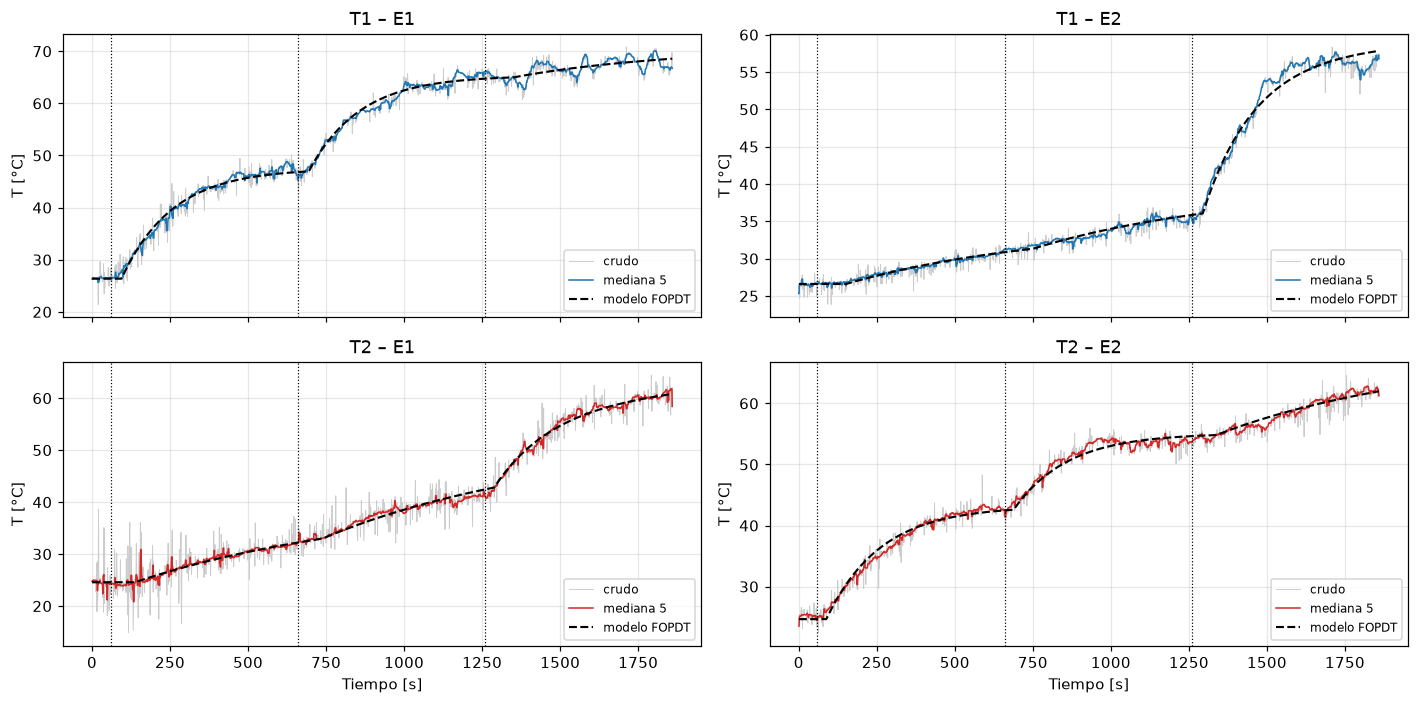

K_C_por_pct           tau_s           theta_s          K_C_por_pct
ensayo          E1     E2       E1       E2       E1       E2    conjunto
canal                                                                    
G11          3.275  2.573  137.868  134.465   15.082   36.873       2.547
G12          0.223  0.897    3.718  418.004  144.177    0.000       0.742
G21          1.591  1.272  305.244  341.618   47.329  199.851       1.723
G22          2.315  2.531  205.147  126.767   19.365    0.000       1.707

El ajuste por ensayo da valores inconsistentes entre E1 y E2 (p. ej. $K_{12}$ = 0.22 vs 0.90, θ = 0 s en algunos canales) porque un solo FOPDT lineal no puede ajustar a la vez el escalón desde ambiente y los siguientes. El ajuste conjunto reduce el RMSE a 0.87 °C (T1) y 0.74 °C (T2).

In [159]:
# Validación: datos que originaron el modelo vs. modelo ajustado
fig, ax = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
for i in range(2):
    for c, (k, d) in enumerate(DATOS.items()):
        t = d['tiempo_s'].values; a = ax[i, c]
        a.plot(t, d[f'T{i+1}_C'], color='0.8', lw=.6, label='crudo')
        a.plot(t, medfilt(d[f'T{i+1}_C'].values, DESPIKE_N), lw=1, color='C0' if i == 0 else 'C3', label='mediana 5')
        a.plot(t, modelo_salida(P_FIT[i], k, t), 'k--', lw=1.4, label='modelo FOPDT')
        for ts in T_PASOS[k]: a.axvline(ts, color='k', ls=':', lw=.8)
        a.set_title(f'T{i+1} – {k}'); a.set_ylabel('T [°C]'); a.legend(fontsize=8)
for a in ax[1]: a.set_xlabel('Tiempo [s]')
fig.tight_layout(); guardar_fig(fig, 'F2_validacion_fopdt.png'); plt.show()

# Comparación con el ajuste de un solo ensayo (programa de adquisición, sin separar el escalón de arranque)
PREV = pd.concat([pd.read_csv(os.path.join(DIR_ID, f.replace('.csv', '_minimos_cuadrados.csv'))).assign(ensayo=k)
                  for k, f in ENSAYOS.items()]).pivot(index='canal', columns='ensayo', values=['K_C_por_pct', 'tau_s', 'theta_s'])
PREV[('K_C_por_pct', 'conjunto')] = [K[int(c[1])-1, int(c[2])-1] for c in PREV.index]
guardar_tabla(PREV, 'comparacion_ajustes.csv'); display(PREV.round(3))
display(Markdown(f"El ajuste por ensayo da valores inconsistentes entre E1 y E2 (p. ej. $K_{{12}}$ = "
                 f"{PREV.loc['G12', ('K_C_por_pct', 'E1')]:.2f} vs {PREV.loc['G12', ('K_C_por_pct', 'E2')]:.2f}, "
                 "θ = 0 s en algunos canales) porque un solo FOPDT lineal no puede ajustar a la vez el escalón desde "
                 f"ambiente y los siguientes. El ajuste conjunto reduce el RMSE a {RMSE[0]:.2f} °C (T1) y {RMSE[1]:.2f} °C (T2)."))

## 3. Fase 2 – Modelo multivariable y diagnóstico de interacción

In [160]:
detK = np.linalg.det(K); condK = np.linalg.cond(K); RGA = K*np.linalg.inv(K).T
display(Math(r"G(s) = \begin{bmatrix} \frac{%.3f\,e^{-%.0fs}}{%.0fs+1} & \frac{%.3f\,e^{-%.0fs}}{%.0fs+1} \\ "
             r"\frac{%.3f\,e^{-%.0fs}}{%.0fs+1} & \frac{%.3f\,e^{-%.0fs}}{%.0fs+1} \end{bmatrix},\qquad "
             r"K = G(0) = \begin{bmatrix} %.3f & %.3f \\ %.3f & %.3f \end{bmatrix}\ \left[\frac{°C}{\%%}\right]"
             % (K[0,0], THETA[0,0], TAU[0,0], K[0,1], THETA[0,1], TAU[0,1],
                K[1,0], THETA[1,0], TAU[1,0], K[1,1], THETA[1,1], TAU[1,1], *K.ravel())))
display(Markdown(f'''
- $\\det(K) = {detK:.3f}$ (°C/%)². Comparado con $K_{{11}}K_{{22}} = {K[0,0]*K[1,1]:.3f}$, el producto cruzado $K_{{12}}K_{{21}} = {K[0,1]*K[1,0]:.3f}$ es el {K[0,1]*K[1,0]/(K[0,0]*K[1,1])*100:.0f} %: la matriz **no está cerca de la singularidad**.
- Número de condición (norma 2, sin normalizar; ambas salidas en °C y ambas entradas en %): $\\kappa(K) = {condK:.2f}$ → condicionamiento moderado; el desacoplador no amplificará mucho el ruido ni el esfuerzo.
- RGA: $\\lambda_{{11}} = {RGA[0,0]:.3f}$ → el emparejamiento diagonal (Q1→T1, Q2→T2) es el correcto (λ11 > 0.5) y la interacción es **moderada** (λ11 entre 1 y 2).
'''))
MATRICES = pd.DataFrame({'K': K.ravel(), 'RGA': RGA.ravel()}, index=['(1,1)', '(1,2)', '(2,1)', '(2,2)'])
display(pd.DataFrame(RGA, index=['T1', 'T2'], columns=['Q1', 'Q2']).round(3).rename_axis('RGA'))

<IPython.core.display.Math object>


- $\det(K) = 3.071$ (°C/%)². Comparado con $K_{11}K_{22} = 4.349$, el producto cruzado $K_{12}K_{21} = 1.278$ es el 29 %: la matriz **no está cerca de la singularidad**.
- Número de condición (norma 2, sin normalizar; ambas salidas en °C y ambas entradas en %): $\kappa(K) = 3.96$ → condicionamiento moderado; el desacoplador no amplificará mucho el ruido ni el esfuerzo.
- RGA: $\lambda_{11} = 1.416$ → el emparejamiento diagonal (Q1→T1, Q2→T2) es el correcto (λ11 > 0.5) y la interacción es **moderada** (λ11 entre 1 y 2).


,Q1,Q2
RGA,,
T1,1.416,-0.416
T2,-0.416,1.416


### 3.1 Interpretación física de las respuestas cruzadas

In [161]:
display(Markdown(f'''
- **Signo:** los cuatro $K_{{ij}}$ son **positivos**: más potencia en cualquier calentador sube ambas temperaturas (el calor solo puede fluir del calentador hacia el resto de la placa y el aire).
- **Magnitud:** los canales directos ($K_{{11}}$ = {K[0,0]:.2f}, $K_{{22}}$ = {K[1,1]:.2f} °C/%) son mayores que los cruzados ($K_{{12}}$ = {K[0,1]:.2f}, $K_{{21}}$ = {K[1,0]:.2f} °C/%): el sensor está pegado a su calentador y al otro llega solo una fracción del calor, después de las pérdidas al ambiente.
- **Asimetría:** $K_{{21}}/K_{{12}}$ = {K[1,0]/K[0,1]:.1f}: el calentador 1 calienta la zona 2 más de lo que el 2 calienta la zona 1. Es consistente con potencias reales distintas en cada calentador (resistencias/cables) o con una ubicación asimétrica de los sensores.
- **Retardo y lentitud:** los canales cruzados tienen más tiempo muerto ($\\theta_{{12}}$ = {THETA[0,1]:.0f} s, $\\theta_{{21}}$ = {THETA[1,0]:.0f} s contra {THETA[0,0]:.0f} y {THETA[1,1]:.0f} s) y constantes de tiempo 4–5 veces mayores ($\\tau_{{12}}$ = {TAU[0,1]:.0f} s, $\\tau_{{21}}$ = {TAU[1,0]:.0f} s): el calor debe atravesar el primer calentador, la placa y el aire antes de llegar al otro sensor (comportamiento casi de segundo orden, aproximado por un FOPDT).
- **Compatibilidad con lo observado:** en E1, con solo Q1 encendido, T2 subió ≈ 7 °C con 5 % (≈ 1.4 °C/%) y en E2, con solo Q2, T1 subió ≈ 4 °C (≈ 0.8 °C/%), del mismo orden que $K_{{21}}$ y $K_{{12}}$.
'''))


- **Signo:** los cuatro $K_{ij}$ son **positivos**: más potencia en cualquier calentador sube ambas temperaturas (el calor solo puede fluir del calentador hacia el resto de la placa y el aire).
- **Magnitud:** los canales directos ($K_{11}$ = 2.55, $K_{22}$ = 1.71 °C/%) son mayores que los cruzados ($K_{12}$ = 0.74, $K_{21}$ = 1.72 °C/%): el sensor está pegado a su calentador y al otro llega solo una fracción del calor, después de las pérdidas al ambiente.
- **Asimetría:** $K_{21}/K_{12}$ = 2.3: el calentador 1 calienta la zona 2 más de lo que el 2 calienta la zona 1. Es consistente con potencias reales distintas en cada calentador (resistencias/cables) o con una ubicación asimétrica de los sensores.
- **Retardo y lentitud:** los canales cruzados tienen más tiempo muerto ($\theta_{12}$ = 91 s, $\theta_{21}$ = 78 s contra 34 y 28 s) y constantes de tiempo 4–5 veces mayores ($\tau_{12}$ = 634 s, $\tau_{21}$ = 751 s): el calor debe atravesar el primer calentador, la placa y el aire antes de llegar al otro sensor (comportamiento casi de segundo orden, aproximado por un FOPDT).
- **Compatibilidad con lo observado:** en E1, con solo Q1 encendido, T2 subió ≈ 7 °C con 5 % (≈ 1.4 °C/%) y en E2, con solo Q2, T1 subió ≈ 4 °C (≈ 0.8 °C/%), del mismo orden que $K_{21}$ y $K_{12}$.


### 3.2 No linealidad
Si la planta fuera lineal, la ganancia del escalón de arranque (desde temperatura ambiente) sería igual a la del punto de operación.

K arranque [°C/%]  K punto de operación [°C/%]  razón
ensayo canal                                                       
E1     G11                 4.22                         2.55   1.66
       G21                 3.05                         1.72   1.77
E2     G12                 1.55                         0.74   2.08
       G22                 3.70                         1.71   2.17

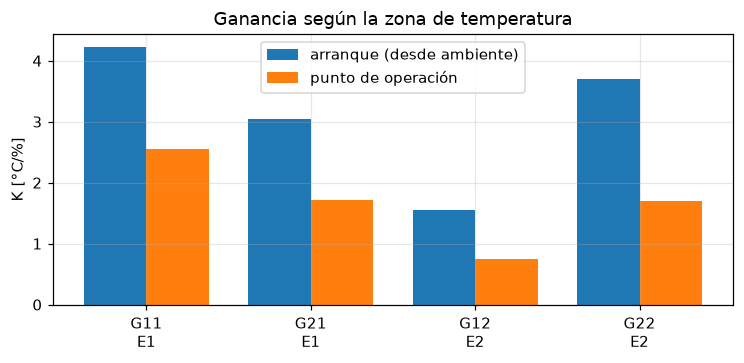

La ganancia de arranque es **1.7–2.2 veces** la del punto de operación: las pérdidas por convección y radiación crecen con la temperatura, así que cada % adicional calienta menos. El modelo lineal solo es válido alrededor del punto de operación.

In [162]:
filas = []
for k in NOMBRES:
    n, j = NOMBRES.index(k), PRINC[k]
    for i in range(2):
        filas.append({'ensayo': k, 'canal': f'G{i+1}{j+1}', 'K arranque [°C/%]': P_FIT[i][6 + 2*n],
                      'K punto de operación [°C/%]': K[i, j]})
NL = pd.DataFrame(filas).set_index(['ensayo', 'canal'])
NL['razón'] = NL['K arranque [°C/%]']/NL['K punto de operación [°C/%]']
guardar_tabla(NL, 'no_linealidad.csv'); display(NL.round(2))
fig, ax = plt.subplots(figsize=(7, 3.4)); x = np.arange(len(NL)); w = .38
ax.bar(x - w/2, NL['K arranque [°C/%]'], w, label='arranque (desde ambiente)')
ax.bar(x + w/2, NL['K punto de operación [°C/%]'], w, label='punto de operación')
ax.set_xticks(x, [f'{c}\n{e}' for e, c in NL.index]); ax.set_ylabel('K [°C/%]'); ax.legend()
ax.set_title('Ganancia según la zona de temperatura'); fig.tight_layout(); guardar_fig(fig, 'F3_no_linealidad.png'); plt.show()
display(Markdown(f"La ganancia de arranque es **{NL['razón'].min():.1f}–{NL['razón'].max():.1f} veces** la del punto de operación: "
                 "las pérdidas por convección y radiación crecen con la temperatura, así que cada % adicional calienta menos. "
                 "El modelo lineal solo es válido alrededor del punto de operación."))

### 3.3 Validación de los modelos frente a los datos que los originaron (simulación con el perfil medido)

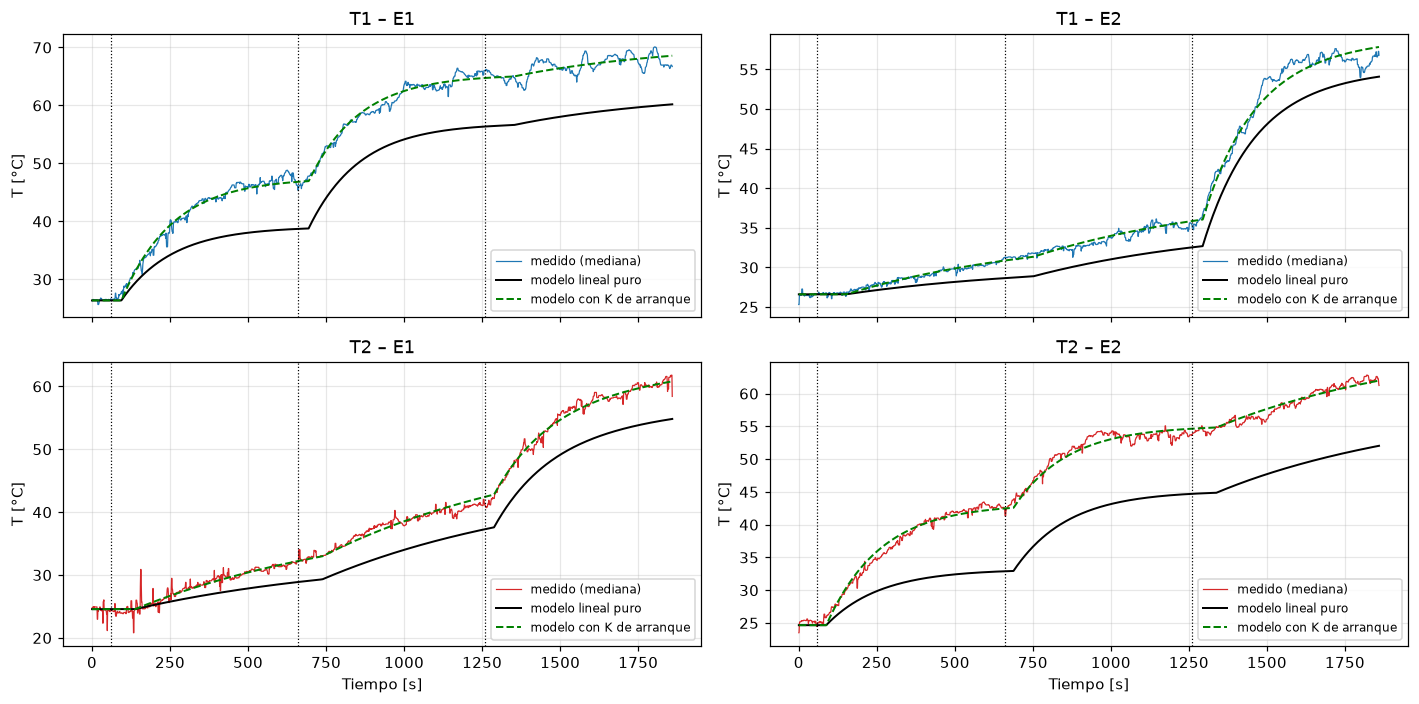

RMSE lineal [°C]  RMSE con arranque [°C]
ensayo salida tramo                                                
E1     T1     base                     0.22                    0.22
              escalon1_Q1              6.47                    0.83
              escalon2_Q1              8.18                    0.88
              cruzado_Q2               8.48                    1.21
       T2     base                     0.72                    0.72
              escalon1_Q1              2.07                    0.70
              escalon2_Q1              4.40                    0.69
              cruzado_Q2               5.70                    0.71
E2     T1     base                     0.33                    0.33
              escalon1_Q2              1.23                    0.23
              escalon2_Q2              2.78                    0.47
              cruzado_Q1               3.88                    1.21
       T2     base                     0.65                    0.65
              escalon1_Q2              7.29                    0.73
              escalon2_Q2             10.06                    0.89
              cruzado_Q1               9.84                    0.69

El modelo lineal puro reproduce bien la **forma** (retardos y constantes de tiempo) pero acumula error de nivel desde el primer tramo por la no linealidad; con la ganancia de arranque separada el error queda en ≈ 0.7 °C, del orden del ruido del sensor.

In [163]:
def sim_perfil(d, T_ini):
    plant = PlantFOPDT(K, TAU, THETA, 1.0); Q = d[['Q1_pct', 'Q2_pct']].values; T = np.zeros_like(Q)
    for n in range(len(Q)):
        T[n] = T_ini + plant.output(); plant.update(Q[n])
    return T
filas = []
fig, ax = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
for c, (k, d) in enumerate(DATOS.items()):
    n = NOMBRES.index(k); t = d['tiempo_s'].values
    T_lin = sim_perfil(d, np.array([P_FIT[0][7 + 2*n], P_FIT[1][7 + 2*n]]))
    T_arr = np.column_stack([modelo_salida(P_FIT[i], k, t) for i in range(2)])
    for i in range(2):
        y = medfilt(d[f'T{i+1}_C'].values, DESPIKE_N); a = ax[i, c]
        a.plot(t, y, color='C0' if i == 0 else 'C3', lw=.8, label='medido (mediana)')
        a.plot(t, T_lin[:, i], 'k', lw=1.3, label='modelo lineal puro')
        a.plot(t, T_arr[:, i], 'g--', lw=1.3, label='modelo con K de arranque')
        for ts in T_PASOS[k]: a.axvline(ts, color='k', ls=':', lw=.8)
        a.set_title(f'T{i+1} – {k}'); a.set_ylabel('T [°C]'); a.legend(fontsize=8)
        for fase in d['fase'].unique():
            m = (d['fase'] == fase).values
            filas.append({'ensayo': k, 'salida': f'T{i+1}', 'tramo': fase,
                          'RMSE lineal [°C]': np.sqrt(np.mean((T_lin[m, i] - y[m])**2)),
                          'RMSE con arranque [°C]': np.sqrt(np.mean((T_arr[m, i] - y[m])**2))})
for a in ax[1]: a.set_xlabel('Tiempo [s]')
fig.tight_layout(); guardar_fig(fig, 'F4_validacion_lazo_abierto.png'); plt.show()
ERR_LA = pd.DataFrame(filas).set_index(['ensayo', 'salida', 'tramo'])
guardar_tabla(ERR_LA, 'validacion_lazo_abierto.csv'); display(ERR_LA.round(2))
display(Markdown("El modelo lineal puro reproduce bien la **forma** (retardos y constantes de tiempo) pero acumula error de "
                 "nivel desde el primer tramo por la no linealidad; con la ganancia de arranque separada el error queda en "
                 f"≈ {ERR_LA['RMSE con arranque [°C]'].mean():.1f} °C, del orden del ruido del sensor."))

## 4. Fase 3 – Diseño y verificación del desacoplador estático

### 4.1 Deducción
Con el desacoplador $D_0 = \begin{bmatrix} 1 & d_{12} \\ d_{21} & 1 \end{bmatrix}$ entre los controladores y la planta, la ganancia estacionaria de $v$ a $\Delta T$ es

$$K D_0 = \begin{bmatrix} K_{11} & K_{12} \\ K_{21} & K_{22} \end{bmatrix}\begin{bmatrix} 1 & d_{12} \\ d_{21} & 1 \end{bmatrix}
= \begin{bmatrix} K_{11} + K_{12}d_{21} & K_{11}d_{12} + K_{12} \\ K_{21} + K_{22}d_{21} & K_{21}d_{12} + K_{22} \end{bmatrix}.$$

Se exige que los elementos fuera de la diagonal sean cero:

$$K_{11}d_{12} + K_{12} = 0 \;\Rightarrow\; d_{12} = -\frac{K_{12}}{K_{11}}, \qquad K_{21} + K_{22}d_{21} = 0 \;\Rightarrow\; d_{21} = -\frac{K_{21}}{K_{22}}.$$

Sustituyendo en la diagonal se obtienen las **ganancias efectivas** que ve cada controlador:

$$K_{11} + K_{12}d_{21} = K_{11} - \frac{K_{12}K_{21}}{K_{22}}, \qquad K_{21}d_{12} + K_{22} = K_{22} - \frac{K_{21}K_{12}}{K_{11}}.$$

Ambas son $\det(K)/K_{22}$ y $\det(K)/K_{11}$: son no nulas porque $\det(K) \neq 0$, y menores que $K_{11}$, $K_{22}$ porque $K_{12}K_{21} > 0$. El desacoplo **resta** del lazo propio la parte de calor que antes aportaba el otro calentador.

In [164]:
D0 = np.array([[1., -K[0, 1]/K[0, 0]], [-K[1, 0]/K[1, 1], 1.]])
KD = K @ D0; K_eff = np.diag(KD)
assert abs(KD[0, 1]) < 1e-9 and abs(KD[1, 0]) < 1e-9, 'K·D0 no es diagonal'
display(Math(r"D_0 = \begin{bmatrix} 1 & %.4f \\ %.4f & 1 \end{bmatrix},\qquad K D_0 = \begin{bmatrix} %.4f & %.1e \\ %.1e & %.4f \end{bmatrix}"
             % (D0[0, 1], D0[1, 0], KD[0, 0], abs(KD[0, 1]), abs(KD[1, 0]), KD[1, 1])))
display(Markdown(f"Ganancias efectivas: **{K_eff[0]:.3f}** y **{K_eff[1]:.3f}** °C/% contra $K_{{11}}$ = {K[0,0]:.3f} y $K_{{22}}$ = {K[1,1]:.3f} "
                 f"(reducción de {(1 - K_eff[0]/K[0,0])*100:.0f} % en ambos lazos, porque $1 - K_{{12}}K_{{21}}/(K_{{11}}K_{{22}}) = 1/\\lambda_{{11}}$)."))
MATRICES['D0'] = D0.ravel(); MATRICES['K·D0'] = KD.ravel()
MATRICES.loc['det(K)', 'K'] = detK; MATRICES.loc['cond(K)', 'K'] = condK
guardar_tabla(MATRICES, 'matrices.csv'); display(MATRICES.round(4))

<IPython.core.display.Math object>

Ganancias efectivas: **1.799** y **1.205** °C/% contra $K_{11}$ = 2.547 y $K_{22}$ = 1.707 (reducción de 29 % en ambos lazos, porque $1 - K_{12}K_{21}/(K_{11}K_{22}) = 1/\lambda_{11}$).

,K,RGA,D0,K·D0
"(1,1)",2.5474,1.4163,1.0000,1.7987
"(1,2)",0.7419,-0.4163,-0.2912,0.0000
"(2,1)",1.7229,-0.4163,-1.0092,-0.0000
"(2,2)",1.7072,1.4163,1.0000,1.2054
det(K),3.0706,NaN,NaN,NaN
cond(K),3.9558,NaN,NaN,NaN


### 4.2 Verificación dinámica: $G(s)$ contra $G(s)D_0$ ante escalones separados en $v_1$ y $v_2$
Lazo abierto, sin controladores, con los retardos representados explícitamente (desplazamiento entero de muestras, sin Padé).

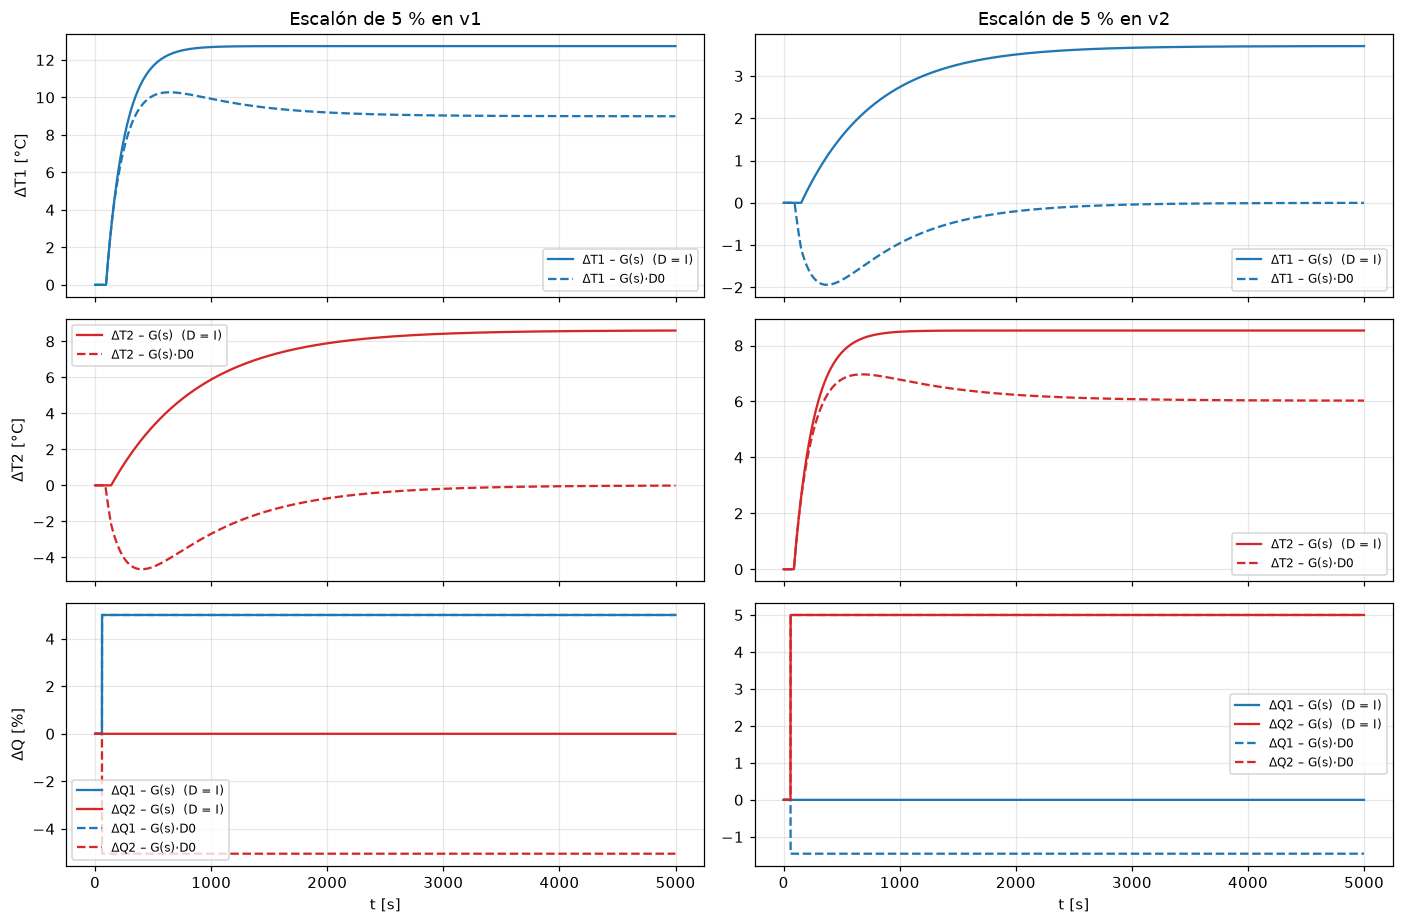

ΔT propio final [°C]  ΔT cruzado final [°C]  ΔT cruzado máx |·| [°C]  instante del máx [s]
escalón  configuración                                                                                            
v1 = 5 % G(s)  (D = I)                12.737                  8.601                    8.601                4939.0
         G(s)·D0                       8.995                 -0.013                    4.662                 343.0
v2 = 5 % G(s)  (D = I)                 8.536                  3.708                    3.708                4939.0
         G(s)·D0                       6.031                 -0.002                    1.941                 313.0


- **Desacoplo estacionario verificado:** con $D_0$ la salida cruzada termina en ≈ 0 (-0.013 y -0.002 °C), contra
  8.60 y 3.71 °C sin desacoplador.
- **Interacción transitoria:** con $D_0$ la salida cruzada se desvía hasta 4.66 °C (escalón en v1) y 1.94 °C (escalón en v2) antes de volver a cero:
  la compensación entra por el canal directo, rápido ($\tau_{22}$ = 173 s, $\theta_{22}$ = 28 s), mientras el efecto que quiere cancelar llega por el canal cruzado, lento ($\tau_{21}$ = 751 s, $\theta_{21}$ = 78 s).
- La salida propia termina en $K_\text{ef}\,v$ (ganancias efectivas), menor que sin desacoplador.


In [165]:
V = 5.0; T_END_LA = 5000.
fig, ax = plt.subplots(3, 2, figsize=(13, 8.5), sharex=True)
filas = []
for c, (nombre, v) in enumerate((('v1', np.array([V, 0.])), ('v2', np.array([0., V])))):
    for lab, Dm, est in (('G(s)  (D = I)', np.eye(2), '-'), ('G(s)·D0', D0, '--')):
        t, dT, dQ = simular_lazo_abierto(K, TAU, THETA, Dm, v, T_END_LA, T_STEP)
        ax[0, c].plot(t, dT[:, 0], est, color='C0', label=f'ΔT1 – {lab}')
        ax[1, c].plot(t, dT[:, 1], est, color='C3', label=f'ΔT2 – {lab}')
        ax[2, c].plot(t, dQ[:, 0], est, color='C0', label=f'ΔQ1 – {lab}'); ax[2, c].plot(t, dQ[:, 1], est, color='C3', label=f'ΔQ2 – {lab}')
        j = 1 - c        # salida "cruzada" para este escalón
        filas.append({'escalón': f'{nombre} = {V:.0f} %', 'configuración': lab,
                      f'ΔT propio final [°C]': dT[-1, c], 'ΔT cruzado final [°C]': dT[-1, j],
                      'ΔT cruzado máx |·| [°C]': np.abs(dT[:, j]).max(),
                      'instante del máx [s]': t[np.argmax(np.abs(dT[:, j]))] - T_STEP})
    ax[0, c].set_title(f'Escalón de {V:.0f} % en {nombre}')
for a in ax[:, 0]: a.legend(fontsize=8)
for a in ax[:, 1]: a.legend(fontsize=8)
ax[0, 0].set_ylabel('ΔT1 [°C]'); ax[1, 0].set_ylabel('ΔT2 [°C]'); ax[2, 0].set_ylabel('ΔQ [%]')
for a in ax[2]: a.set_xlabel('t [s]')
fig.tight_layout(); guardar_fig(fig, 'F5_verificacion_desacoplador.png'); plt.show()
VERIF_D0 = pd.DataFrame(filas).set_index(['escalón', 'configuración'])
guardar_tabla(VERIF_D0, 'verificacion_desacoplador.csv'); display(VERIF_D0.round(3))
R_D0 = VERIF_D0.xs('G(s)·D0', level=1)
display(Markdown(f'''
- **Desacoplo estacionario verificado:** con $D_0$ la salida cruzada termina en ≈ 0 ({R_D0.iloc[0]['ΔT cruzado final [°C]']:+.3f} y {R_D0.iloc[1]['ΔT cruzado final [°C]']:+.3f} °C), contra
  {VERIF_D0.iloc[0]['ΔT cruzado final [°C]']:.2f} y {VERIF_D0.iloc[2]['ΔT cruzado final [°C]']:.2f} °C sin desacoplador.
- **Interacción transitoria:** con $D_0$ la salida cruzada se desvía hasta {R_D0.iloc[0]['ΔT cruzado máx |·| [°C]']:.2f} °C (escalón en v1) y {R_D0.iloc[1]['ΔT cruzado máx |·| [°C]']:.2f} °C (escalón en v2) antes de volver a cero:
  la compensación entra por el canal directo, rápido ($\\tau_{{22}}$ = {TAU[1,1]:.0f} s, $\\theta_{{22}}$ = {THETA[1,1]:.0f} s), mientras el efecto que quiere cancelar llega por el canal cruzado, lento ($\\tau_{{21}}$ = {TAU[1,0]:.0f} s, $\\theta_{{21}}$ = {THETA[1,0]:.0f} s).
- La salida propia termina en $K_\\text{{ef}}\\,v$ (ganancias efectivas), menor que sin desacoplador.
'''))

### 4.3 Realizabilidad física de las potencias

In [166]:
# Punto de operación medido: potencias medias con T1, T2 ≈ 55–57 °C en una aproximación en lazo cerrado del 23-oct
# (tramo 700–900 s, antes de que fallara el sensor 2)
_a3 = pd.read_csv(f'{DIR_QOP}/lc_S1_A_20261023_155431.csv')
_m = (_a3['tiempo_s'] >= 700) & (_a3['tiempo_s'] <= 900)
Q_OP = _a3.loc[_m, ['Q1_pct', 'Q2_pct']].mean().round(1).to_numpy()
T_med = _a3.loc[_m, ['T1_filt_C', 'T2_filt_C']].mean().to_numpy()
PUNTO_OP = pd.DataFrame({'T_OP [°C]': T_OP, 'Q_OP [%]': Q_OP, 'T medida al obtener Q_OP [°C]': T_med},
                        index=['zona 1', 'zona 2'])
guardar_tabla(PUNTO_OP, 'punto_operacion.csv'); display(PUNTO_OP.round(2))

filas = []
Kinv = np.linalg.inv(K)
for s, ref in SCEN.items():
    dQ_ss = Kinv @ ref                      # igual con y sin D0: en estado estacionario Q = Q_OP + K^-1 Δr
    for cfg, Dm in (('A', np.eye(2)), ('B', D0)):
        v_ss = np.linalg.solve(K @ Dm, ref)
        filas.append({'escenario': s, 'config': cfg, 'v1 ee': v_ss[0], 'v2 ee': v_ss[1],
                      'Q1 ee [%]': Q_OP[0] + dQ_ss[0], 'Q2 ee [%]': Q_OP[1] + dQ_ss[1]})
REAL = pd.DataFrame(filas).set_index(['escenario', 'config'])
REAL['dentro de [0, QMAX]'] = REAL[['Q1 ee [%]', 'Q2 ee [%]']].apply(lambda r: bool(((r >= QMIN) & (r <= QMAX)).all()), axis=1)
guardar_tabla(REAL, 'realizabilidad_estacionaria.csv'); display(REAL.round(3))
display(Markdown(f'''
- En estado estacionario la potencia necesaria es la misma con y sin desacoplador ($Q = Q_{{OP}} + K^{{-1}}\\Delta r$); cambia la señal virtual $v$ y, sobre todo, el **transitorio**.
- $d_{{21}}$ = {D0[1,0]:.2f} ≈ −1: cuando el lazo 1 pide potencia, el desacoplador **resta casi lo mismo a $Q_2$**. Con $Q_{{2,OP}}$ = {Q_OP[1]:.1f} %, el margen hacia 0 % es pequeño: un aumento de $v_1$ mayor que ≈ {Q_OP[1]/abs(D0[1,0]):.1f} % satura $Q_2$ en 0 % y en ese instante el desacoplo deja de cumplirse.
- Todos los escenarios son realizables en estado estacionario con la saturación de 0–{QMAX:.0f} %; el transitorio se revisa con las potencias **solicitadas** y **aplicadas** en la sección 5.
'''))

,T_OP [°C],Q_OP [%],T medida al obtener Q_OP [°C]
zona 1,55.0,6.6,56.56
zona 2,55.0,6.6,56.17


v1 ee  v2 ee  Q1 ee [%]  Q2 ee [%]  dentro de [0, QMAX]
escenario config                                                         
S1        A       2.780 -2.806      9.380      3.794                 True
          B       2.780  0.000      9.380      3.794                 True
S2        A      -1.208  4.148      5.392     10.748                 True
          B       0.000  4.148      5.392     10.748                 True
S3        A       2.055 -0.317      8.655      6.283                 True
          B       2.780  2.489      8.655      6.283                 True


- En estado estacionario la potencia necesaria es la misma con y sin desacoplador ($Q = Q_{OP} + K^{-1}\Delta r$); cambia la señal virtual $v$ y, sobre todo, el **transitorio**.
- $d_{21}$ = -1.01 ≈ −1: cuando el lazo 1 pide potencia, el desacoplador **resta casi lo mismo a $Q_2$**. Con $Q_{2,OP}$ = 6.6 %, el margen hacia 0 % es pequeño: un aumento de $v_1$ mayor que ≈ 6.5 % satura $Q_2$ en 0 % y en ese instante el desacoplo deja de cumplirse.
- Todos los escenarios son realizables en estado estacionario con la saturación de 0–30 %; el transitorio se revisa con las potencias **solicitadas** y **aplicadas** en la sección 5.


## 5. Fase 4 – Diseño de los controladores PI

### 5.1 Método de sintonización: IMC para FOPDT
Para cada lazo diagonal $G_{ii}(s) = K_d\,e^{-\theta s}/(\tau s + 1)$, con aproximación de primer orden del retardo, la regla IMC da un PI:

$$K_p = \frac{\tau + \theta/2}{K_d\,(\lambda + \theta/2)}, \qquad T_i = \tau + \theta/2, \qquad K_I = \frac{K_p}{T_i}, \qquad K_D = 0,$$

con $\lambda = 1.5\,\tau$ (conservador: el 27-oct, con $\lambda = 0.8\,\tau$, los lazos oscilaron en el equipo). $K_d$ = ganancia del canal diagonal ($K_{11}$, $K_{22}$).

**¿Por qué PI y no PID?** La razón $\theta/\tau \approx 0.2$ es pequeña (proceso dominado por la constante de tiempo, donde la derivada aporta poco) y el ruido de los sensores es alto (picos de varios °C, sección 2.1): la acción derivativa los amplificaría directamente sobre la potencia. El enunciado acepta PI con esta justificación.

**Comparación justa:** los mismos $C_1$, $C_2$ se usan en A ($D_0 = I$) y B ($D_0$ identificado). Se diseña sobre $K_{11}$, $K_{22}$ (no sobre las ganancias efectivas) para no favorecer a ninguna configuración; el efecto del cambio de ganancia se discute en la pregunta 5.

### 5.2 Implementación digital (igual en simulación y en el equipo, `codigo/mimo_control.py`)
- $T_s = 1$ s. Medición filtrada con **mediana de 5 muestras** (quita picos sin desfase apreciable frente a θ ≈ 30 s).
- Ley de control: $v = C(s)\,e$, $\;Q_\text{sol} = Q_{OP} + D_0 v$, $\;Q_\text{apl} = \mathrm{sat}_{[0,\,30\%]}(Q_\text{sol})$.
- **Anti-windup por back-calculation:** $\dot I = K_I e + (v_\text{apl} - v)/T_t$, con $v_\text{apl} = D_0^{-1}(Q_\text{apl} - Q_{OP})$ y $T_t = T_i/2$. Así el integrador no sigue creciendo cuando una potencia está saturada, aunque la saturación la produzca el término cruzado del desacoplador.
- **Estado de los integradores:** se inicializan en 0 al comenzar cada ensayo (igual para A y B). Como $Q_{OP}$ es la potencia medida en el punto de operación, $v \approx 0$ en equilibrio y el arranque no produce saltos. No se cambia de configuración durante un ensayo: A y B son ensayos separados, cada uno con su propia aproximación al punto de operación; al detener un ensayo las potencias van a 0 y el integrador se descarta.

In [167]:
Kd = np.diag(K); tau_d, th_d = np.diag(TAU), np.diag(THETA)
lam = LAMBDA_FACTOR*tau_d
Kp = (tau_d + th_d/2)/(Kd*(lam + th_d/2)); Ti = tau_d + th_d/2
PI_TAB = pd.DataFrame({'Kp [%/°C]': Kp, 'KI [%/(°C·s)]': Kp/Ti, 'KD [%·s/°C]': [0., 0.], 'Ti [s]': Ti,
                       'λ [s]': lam, 'Kd usado [°C/%]': Kd, 'Ts [s]': [Ts, Ts]}, index=['C1 (T1←Q1)', 'C2 (T2←Q2)'])
guardar_tabla(PI_TAB, 'sintonia_PI.csv'); display(PI_TAB.round(5))

,Kp [%/°C],KI [%/(°C·s)],KD [%·s/°C],Ti [s],λ [s],Kd usado [°C/%],Ts [s]
C1 (T1←Q1),0.27028,0.00150,0.0,180.58488,245.07491,2.54744,1.0
C2 (T2←Q2),0.40060,0.00214,0.0,186.92383,259.20434,1.70717,1.0


### 5.3 Simulación: estabilidad y seguimiento (modelo identificado, saturación 0–30 %)

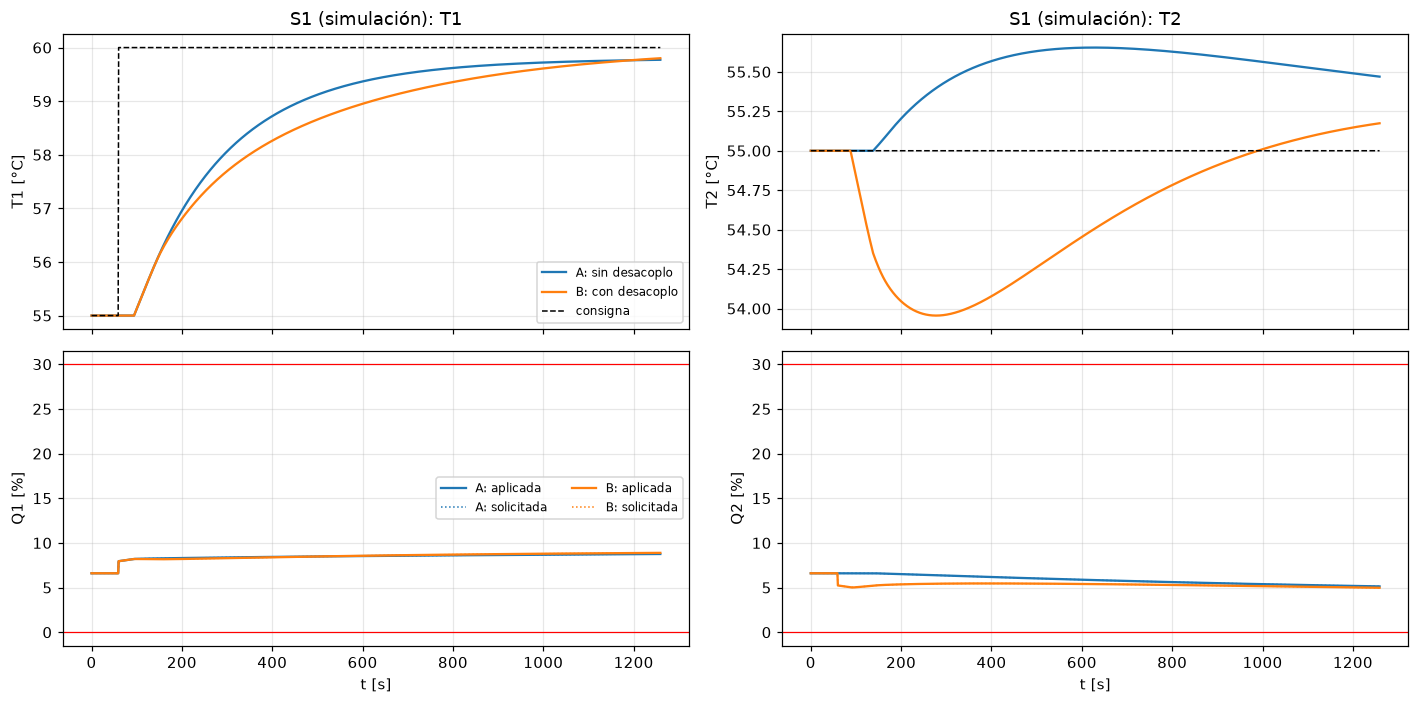

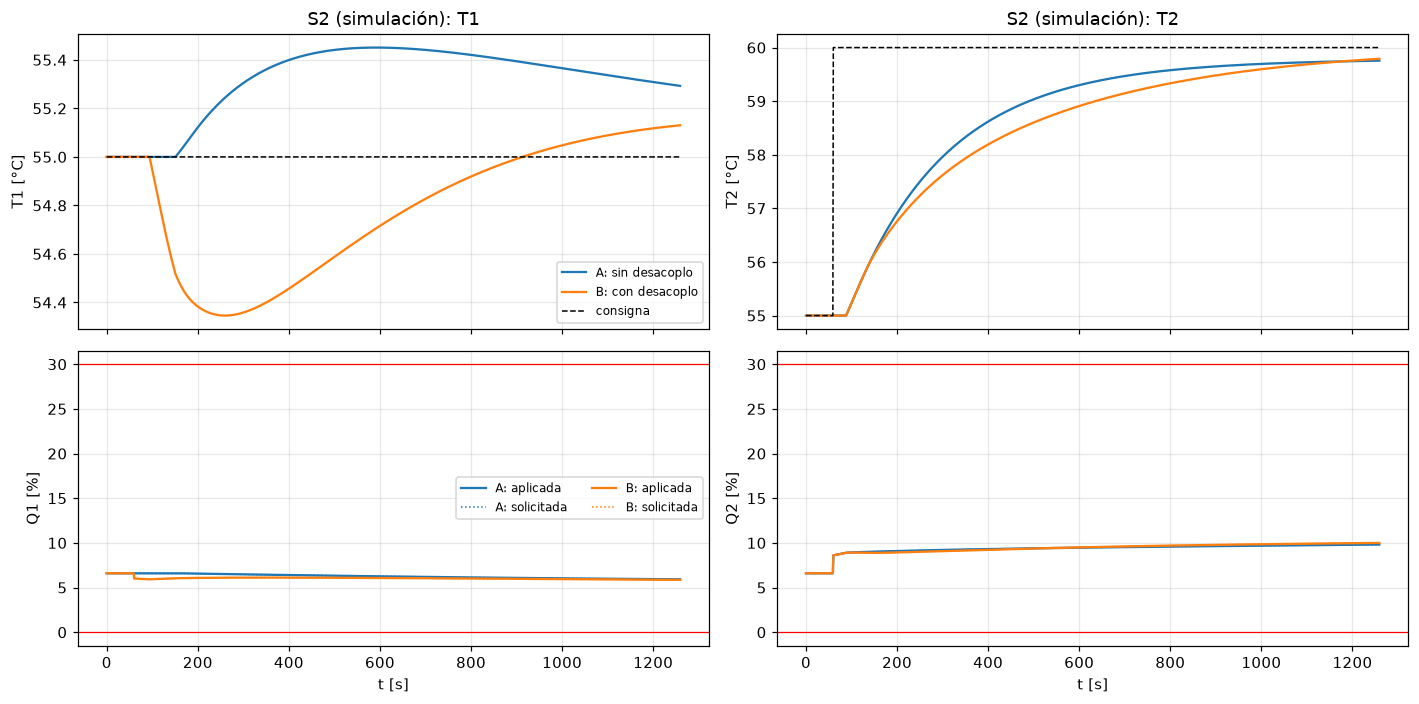

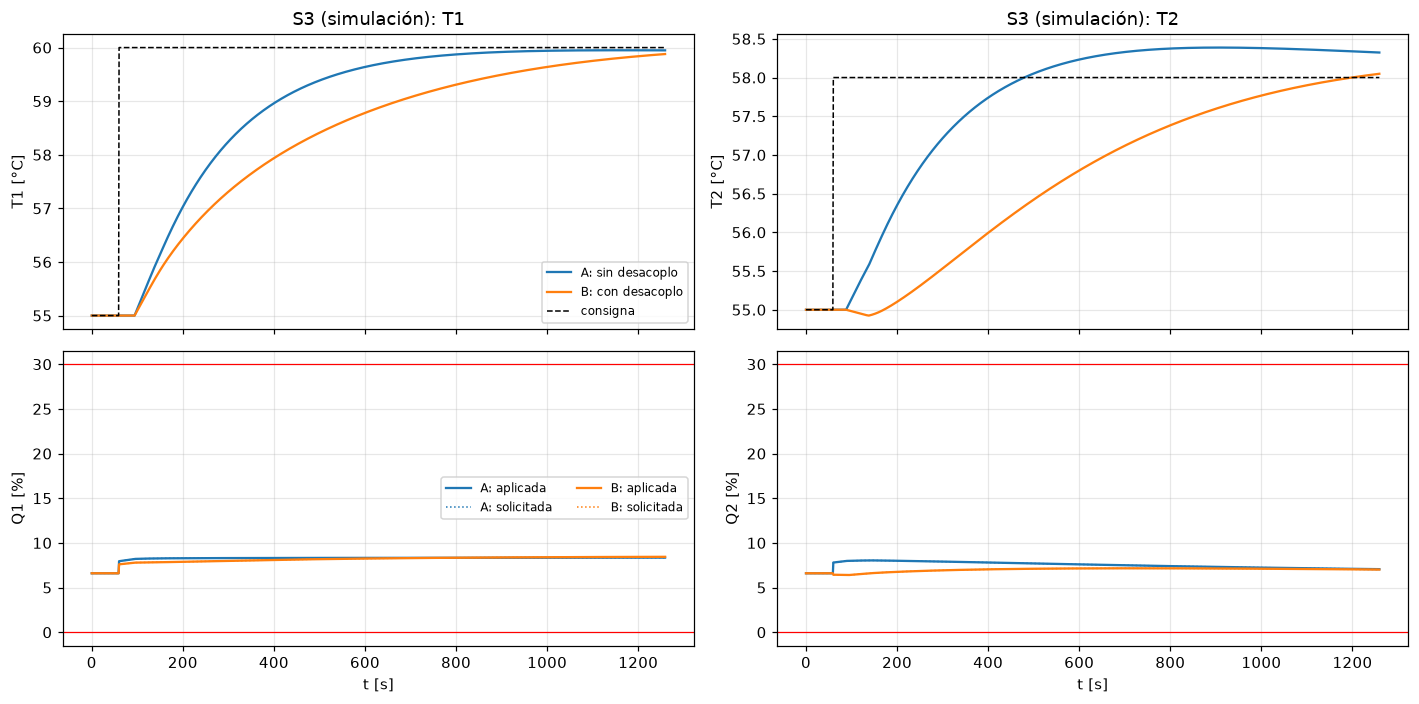

Los seis casos simulados son **estables** y siguen la consigna sin error estacionario (acción integral). Ninguna potencia toca los límites de 0 y 30 % en estos escenarios (tabla de la sección 7).

In [168]:
SIM = {s: {cfg: simular_lazo_cerrado(K, TAU, THETA, Dm, Kp, Ti, ref, T_OP, Q_OP, QMIN, QMAX, T_STEP + T_POST, T_STEP)
           for cfg, Dm in (('A', np.eye(2)), ('B', D0))} for s, ref in SCEN.items()}
for s in SCEN:
    fig, ax = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
    for i in range(2):
        for cfg, col in (('A', 'C0'), ('B', 'C1')):
            o = SIM[s][cfg]
            ax[0, i].plot(o['t'], o['T'][:, i], color=col, label=f'{cfg}: {"sin" if cfg == "A" else "con"} desacoplo')
            ax[1, i].plot(o['t'], o['Q'][:, i], color=col, label=f'{cfg}: aplicada')
            ax[1, i].plot(o['t'], o['Q_cmd'][:, i], ':', color=col, lw=1, label=f'{cfg}: solicitada')
        ax[0, i].plot(o['t'], o['r_abs'][:, i], 'k--', lw=1, label='consigna')
        for q in (QMIN, QMAX): ax[1, i].axhline(q, color='r', lw=.8)
        ax[0, i].set_title(f'{s} (simulación): T{i+1}'); ax[0, i].set_ylabel(f'T{i+1} [°C]')
        ax[1, i].set_ylabel(f'Q{i+1} [%]'); ax[1, i].set_xlabel('t [s]')
    ax[0, 0].legend(fontsize=8); ax[1, 0].legend(fontsize=8, ncol=2)
    fig.tight_layout(); guardar_fig(fig, f'F6_simulacion_{s}.png'); plt.show()
display(Markdown("Los seis casos simulados son **estables** y siguen la consigna sin error estacionario (acción integral). "
                 "Ninguna potencia toca los límites de 0 y 30 % en estos escenarios (tabla de la sección 7)."))

### 5.4 Validación de consignas 
- [ ] Punto de operación $T_{OP}$ = 55 °C en ambas zonas, escalones de +5 °C (S1, S2) y +5/+3 °C (S3).
- [ ] Saturación 0–30 %, corte de seguridad 110 °C y protecciones de la sección 1.2.


## 6. Fase 5 – Pruebas comparativas A/B

**Protocolo (idéntico para A y B):** $T_s$ = 1 s; aproximación en lazo cerrado a $T_{OP}$ con la configuración del ensayo y la consigna en **rampa de 3 °C/min** desde la temperatura inicial (el enunciado pide evitar cambios bruscos de consigna; reduce el sobrepaso de la aproximación); el escalón se aplica cuando ambas temperaturas (promedio de 30 s) llevan 120 s dentro de ±0.7 °C de $T_{OP}$; se registran 1200 s después del escalón (≈ 7 constantes de tiempo del lazo cerrado, λ + θ ≈ 165 s). Orden: S1-A, S1-B, S2-A, S2-B (alternando A y B), con el equipo frío al inicio de cada ensayo. Si en 1500 s de aproximación no se cumple el criterio de estabilidad, el escalón se aplica de todos modos y queda anotado en el registro (tabla de condiciones de la sección 6.1). Se registran $T_1, T_2, r_{1,abs}, r_{2,abs}, v_1, v_2$, $Q$ solicitada y aplicada, la configuración y el motivo de fin. El código que los ejecuta está en la sección 6.0.

### 6.1 Ensayos en el equipo

### 6.0 Código de los ensayos en lazo cerrado
Usa los PI de la sección 5 (`Kp`, `Ti`), $D_0$ de la sección 4 y $Q_{OP}$ de la sección 4.3: aproximación a $T_{OP}$ con la consigna en rampa de 3 °C/min desde la temperatura inicial → escalón automático cuando ambas temperaturas (promedio de 30 s) llevan 120 s en ±0.7 °C de $T_{OP}$ (o a los 1500 s, con aviso) → 1200 s de respuesta. Integradores en cero al iniciar. Guarda CSV, metadatos, figura e indicadores en `datos/lazo_cerrado/`.

In [169]:
def ensayo_lazo_cerrado(escenario, caso):
    D = D0 if caso == 'B' else np.eye(2); Dinv = np.linalg.inv(D); ref = np.array(SCEN[escenario])
    path = nombre_libre(os.path.join(DIR_LC, f'lc_{escenario}_{caso}'), '.csv'); base = path[:-4]
    print(f'{escenario}-{caso} ({"con" if caso == "B" else "sin"} desacoplo) | escalón {ref} °C sobre T_OP = {T_OP} °C\nD =\n{D}')
    v = Ventana(f'Lazo cerrado {escenario} – caso {caso}: escalón {ref.tolist()} °C sobre T_OP = {T_OP.tolist()} °C', True)
    ctrl, vg = PI2(Kp, Ti), Vigilante()
    t, T1, T2, Tf, R, Qa = [], [], [], [], [], []
    t_esc = t_estable = t_prev = y0 = None; motivo = 'perfil completo'; aviso = ''
    cols = ['tiempo_s', 'fase', 'r1_C', 'r2_C', 'T1_C', 'T2_C', 'T1_filt_C', 'T2_filt_C', 'v1', 'v2',
            'Q1_cmd_pct', 'Q2_cmd_pct', 'Q1_pct', 'Q2_pct', 'vigilante']
    f = open(path, 'w', newline='', encoding='utf-8'); wr = csv.writer(f); wr.writerow(cols)
    with tclab.TCLab() as lab:
        apagar(lab); print(f'T inicial: T1 = {lab.T1:.2f} °C, T2 = {lab.T2:.2f} °C')
        t0 = time.perf_counter(); k = 0
        try:
            while True:
                plt.pause(max(k*TS - (time.perf_counter() - t0), 0.001)); now = time.perf_counter() - t0
                dt = TS if t_prev is None else now - t_prev; t_prev = now
                if not v.abierta(): motivo = 'ventana cerrada por el usuario'; break
                if t_esc is not None and now >= t_esc + T_POST: break
                a, b = lab.T1, lab.T2; T1.append(a); T2.append(b)
                y = np.array([np.median(T1[-FILT_N:]), np.median(T2[-FILT_N:])])
                med = [np.median(T1[-T_MAX_N:]), np.median(T2[-T_MAX_N:])]
                if max(med) >= T_MAX:
                    motivo = f'LÍMITE DE TEMPERATURA ({T_MAX:.0f} °C): mediana T1={med[0]:.1f}, T2={med[1]:.1f} °C'; break
                if t_esc is None:                                   # ¿aplicar el escalón?
                    n_avg = max(1, int(round(STEADY_AVG_S/TS))); y_avg = np.mean(np.array(Tf[-n_avg:] + [y]), axis=0)
                    t_estable = (t_estable or now) if np.all(np.abs(y_avg - T_OP) < STEADY_TOL) else None
                    estable = t_estable is not None and now - t_estable >= STEADY_S
                    if (estable and now >= T_APPROACH_MIN) or now >= T_APPROACH_MAX:
                        t_esc = now
                        if not estable:
                            aviso = f'escalón sin estado estable (límite {T_APPROACH_MAX:.0f} s), T_f = {y.round(2).tolist()}'; print('[aviso]', aviso)
                        print(f'[{now:7.1f} s] ESCALÓN: r = {(T_OP + ref).tolist()} °C')
                        v.marca(now)
                if y0 is None: y0 = y.copy()                    # temperatura inicial: arranque de la rampa
                r_aprox = y0 + np.clip(T_OP - y0, -RAMPA_C_S*now, RAMPA_C_S*now)
                r = (T_OP + ref) if t_esc is not None else r_aprox
                vv, q_cmd, q_app = paso_control(ctrl, D, Dinv, Q_OP, QMIN, QMAX, r, y, dt)
                lab.Q1(q_app[0]); lab.Q2(q_app[1])
                alarma = vg.revisar(now, [a, b], q_app, r - y)
                t.append(now); Tf.append(y); R.append(r); Qa.append(q_app)
                wr.writerow([f'{now:.3f}', 'respuesta' if t_esc is not None else 'aproximacion', r[0], r[1], f'{a:.3f}', f'{b:.3f}',
                             f'{y[0]:.3f}', f'{y[1]:.3f}', f'{vv[0]:.4f}', f'{vv[1]:.4f}', f'{q_cmd[0]:.3f}', f'{q_cmd[1]:.3f}',
                             f'{q_app[0]:.3f}', f'{q_app[1]:.3f}', alarma or '']); f.flush()
                if alarma: motivo = f'ANOMALÍA: {alarma}'; break
                Ra, Qx = np.array(R), np.array(Qa)
                v.actualizar(t, {'T1': T1, 'T2': T2, 'r1': Ra[:, 0], 'r2': Ra[:, 1], 'Q1': Qx[:, 0], 'Q2': Qx[:, 1]},
                             (t_esc + T_POST) if t_esc is not None else max(now, 60)*1.05)
                if k % 60 == 0:
                    est = f'faltan {(t_esc + T_POST - now)/60:4.1f} min' if t_esc is not None else \
                          f'aproximando, estable {0 if t_estable is None else now - t_estable:3.0f} s'
                    print(f'[{now:7.1f} s] T1={y[0]:6.2f} T2={y[1]:6.2f} °C  Q1={q_app[0]:5.1f} Q2={q_app[1]:5.1f} %  ({est})')
                k += 1
        except KeyboardInterrupt:
            motivo = 'abortado por el usuario'
        except Exception as ex:
            motivo = f'ERROR ({type(ex).__name__}: {ex})'
        finally:
            apagar(lab); f.close()
    v.guardar(base + '.png')
    meta = {'fecha': f'{datetime.datetime.now():%Y-%m-%d %H:%M:%S}', 'escenario': escenario, 'caso': caso,
            'escalon_ref_C': ref.tolist(), 'T_OP_C': T_OP.tolist(), 'Q_OP_pct': Q_OP.tolist(), 'QMIN_QMAX_pct': [QMIN, QMAX],
            'Kp': Kp.round(5).tolist(), 'Ti_s': Ti.round(3).tolist(), 'D': D.round(5).tolist(), 'Ts_s': TS,
            'filtro_mediana_N': FILT_N, 't_escalon_s': None if t_esc is None else round(t_esc, 3), 'T_post_s': T_POST,
            'aviso_escalon': aviso, 'rampa_aprox_C_s': RAMPA_C_S, 'T_max_C': T_MAX, 'motivo_fin': motivo}
    with open(base + '_meta.txt', 'w', encoding='utf-8') as fm:
        fm.write('\n'.join(f'{k_}: {v_}' for k_, v_ in meta.items()) + '\n')
    completo = motivo == 'perfil completo'
    print('#'*78 + f'\n#  {escenario}-{caso}: {"COMPLETO" if completo else "INCOMPLETO"} – {motivo}\n#  Calentadores apagados. Datos: {path}\n' + '#'*78)
    if t_esc is not None and t[-1] - t_esc > 60:
        dd = pd.read_csv(path)
        ind = indicadores(dd['tiempo_s'], dd[['T1_filt_C', 'T2_filt_C']].values, dd[['r1_C', 'r2_C']].values,
                          dd[['Q1_cmd_pct', 'Q2_cmd_pct']].values, dd[['Q1_pct', 'Q2_pct']].values, t_esc, ref, QMIN, QMAX)
        IND = pd.DataFrame([ind], index=[f'{escenario}-{caso}']); IND.to_csv(base + '_indicadores.csv'); display(IND.T)
    registrar(f'{escenario}-{caso}', path, 'COMPLETO' if completo else 'INCOMPLETO', motivo, aviso)
    if os.path.exists(base + '.png'): display(Image(base + '.png'))
    return completo

In [170]:
ENSAYO = None   # ('S1', 'A'), ('S1', 'B'), ('S2', 'A') o ('S2', 'B'): uno a la vez y con el equipo frío
if EJECUTAR_EQUIPO and ENSAYO:
    en_ventana(ensayo_lazo_cerrado, *ENSAYO)
else:
    print('Sin ensayo nuevo: se usan los ensayos guardados en datos/lazo_cerrado/.')

Sin ensayo nuevo: se usan los ensayos guardados en datos/lazo_cerrado/.


archivo                fecha  ΔT1 al escalón [°C]  ΔT2 al escalón [°C]                escalón aplicado por
escenario config                                                                                                                                
S1        A       lc_S1_A_20261028_123554.csv  2026-10-28 13:21:00                 0.56                 0.06  tiempo límite (sin estado estable)
          B       lc_S1_B_20261028_134116.csv  2026-10-28 14:26:21                -0.06                -1.30  tiempo límite (sin estado estable)
S2        A       lc_S2_A_20261028_143733.csv  2026-10-28 15:22:39                 0.60                -1.51  tiempo límite (sin estado estable)
          B       lc_S2_B_20261028_153133.csv  2026-10-28 16:16:39                 1.08                -0.11  tiempo límite (sin estado estable)

**Condiciones reales de los ensayos.** 4 de 4 escalones se aplicaron al cumplirse el tiempo límite de la aproximación (1500 s), sin que ambas temperaturas llevaran 120 s dentro de ±0.7 °C; en ese momento las temperaturas estaban hasta 1.5 °C fuera de $T_{OP}$. El lazo seguía corrigiendo esa desviación después del escalón, y eso se suma a la interacción medida (sobre todo cuando la otra zona partía lejos de 55 °C) y al error de seguimiento. El ruido del sensor 2 (picos aislados de ±2 °C, sección 2.1) es mayor que la banda de ±5 % de un escalón de 5 °C (±0.25 °C): infla el sobreimpulso de $T_2$ y puede dejar $t_s$ sin establecer aunque la respuesta media ya esté en la consigna. Entre ensayos se esperó a que el equipo se enfriara; el 28-oct se usó la fuente original, PI con λ = 1.5τ y saturación de 30 % (sección 1.2).

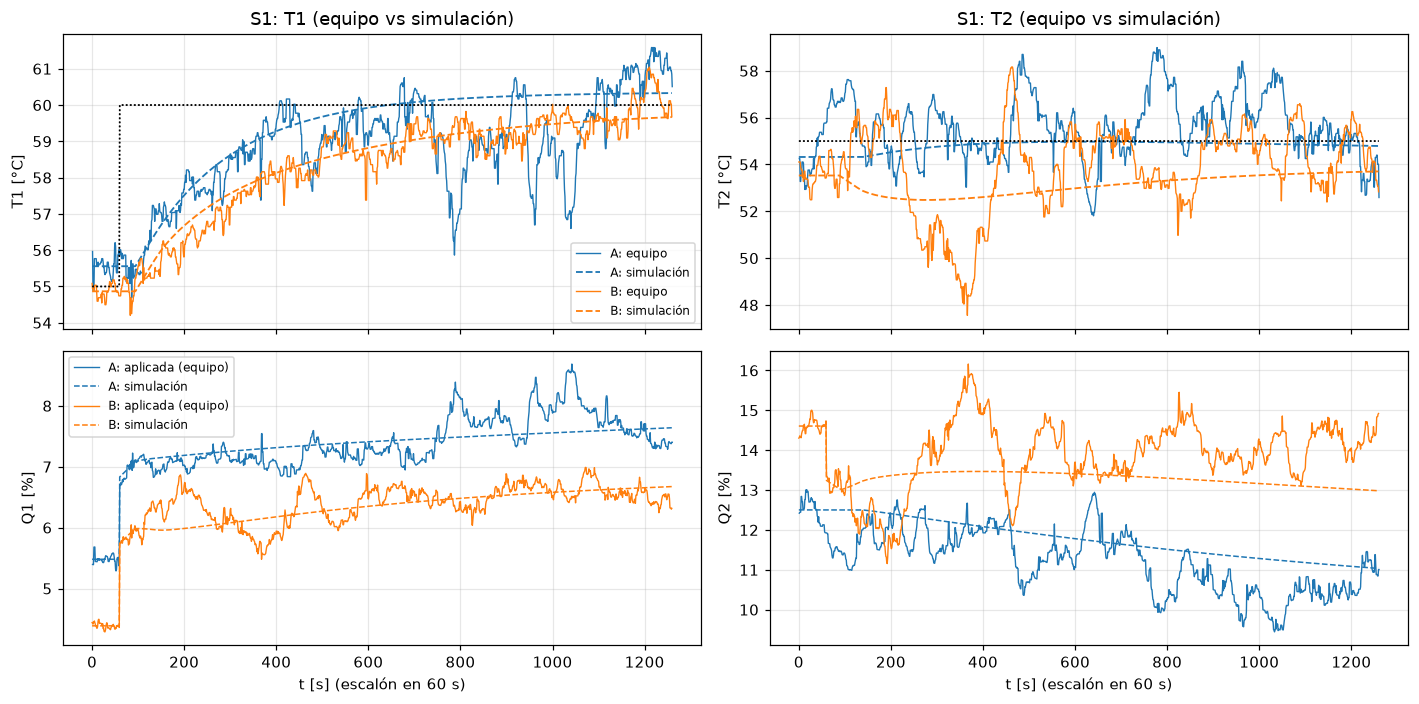

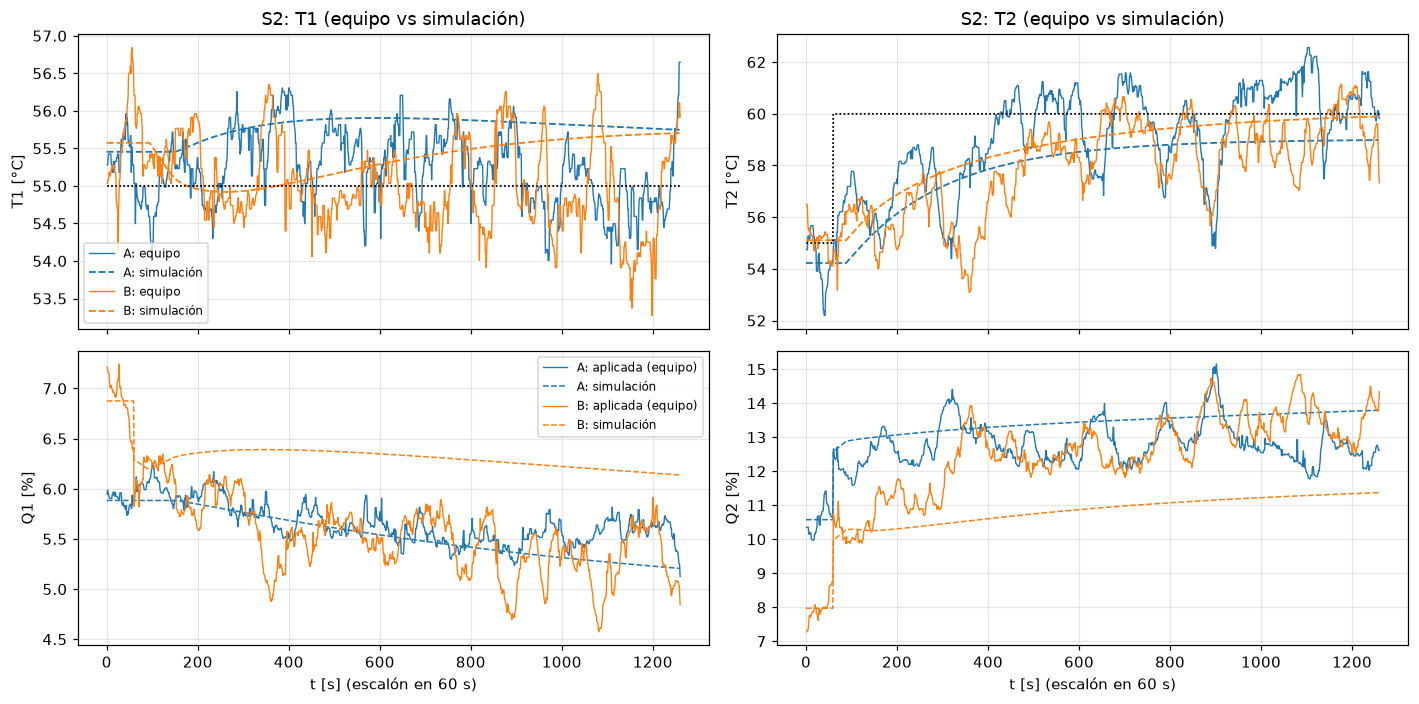

In [171]:
def ultimo_completo(escenario, caso):
    # Ensayo más reciente y COMPLETO de un escenario/caso en datos/lazo_cerrado
    cands = []
    for m in glob.glob(os.path.join(DIR_LC, f'lc_{escenario}_{caso}*_meta.txt')):
        d = leer_meta(m)
        if d.get('motivo_fin') == 'perfil completo' and d.get('t_escalon_s') not in (None, 'None'):
            cands.append((d.get('fecha'), m.replace('_meta.txt', '.csv'), float(d['t_escalon_s'])))
    return max(cands) if cands else None

REALES = {}
for s in SCEN:
    for cfg in ('A', 'B'):
        sel = ultimo_completo(s, cfg)
        if sel is None: continue
        _, archivo, t_esc = sel; d = pd.read_csv(archivo)
        t = d['tiempo_s'].values - t_esc + T_STEP                      # escalón alineado con la simulación
        T = np.column_stack([medfilt(d[f'T{i+1}_C'].values, DESPIKE_N) for i in range(2)])
        REALES[(s, cfg)] = {'archivo': archivo, 't': t, 'T': T, 'r_abs': d[['r1_C', 'r2_C']].values,
                            'Q_cmd': d[['Q1_cmd_pct', 'Q2_cmd_pct']].values, 'Q': d[['Q1_pct', 'Q2_pct']].values,
                            'v': d[['v1', 'v2']].values}
if REALES:
    # Condiciones al aplicar el escalón: desviación de T respecto a T_OP (promedio de los 30 s previos) y motivo
    COND = []
    for (s, c), r in REALES.items():
        mt = leer_meta(r['archivo'].replace('.csv', '_meta.txt'))
        dT = r['T'][(r['t'] >= T_STEP - 30) & (r['t'] < T_STEP)].mean(axis=0) - T_OP
        COND.append({'escenario': s, 'config': c, 'archivo': os.path.basename(r['archivo']), 'fecha': mt.get('fecha'),
                     'ΔT1 al escalón [°C]': dT[0], 'ΔT2 al escalón [°C]': dT[1],
                     'escalón aplicado por': 'tiempo límite (sin estado estable)' if mt.get('aviso_escalon') else 'estado estable'})
    COND = pd.DataFrame(COND).set_index(['escenario', 'config']); display(COND.round(2))
    n_lim = (COND['escalón aplicado por'] != 'estado estable').sum()
    DEV_MAX = COND[['ΔT1 al escalón [°C]', 'ΔT2 al escalón [°C]']].abs().max().max()
    display(Markdown(f'''**Condiciones reales de los ensayos.** {n_lim} de {len(COND)} escalones se aplicaron al cumplirse el tiempo límite de la aproximación (1500 s), sin que ambas temperaturas llevaran 120 s dentro de ±0.7 °C; en ese momento las temperaturas estaban hasta {DEV_MAX:.1f} °C fuera de $T_{{OP}}$. El lazo seguía corrigiendo esa desviación después del escalón, y eso se suma a la interacción medida (sobre todo cuando la otra zona partía lejos de 55 °C) y al error de seguimiento. El ruido del sensor 2 (picos aislados de ±2 °C, sección 2.1) es mayor que la banda de ±5 % de un escalón de 5 °C (±0.25 °C): infla el sobreimpulso de $T_2$ y puede dejar $t_s$ sin establecer aunque la respuesta media ya esté en la consigna. Entre ensayos se esperó a que el equipo se enfriara; el 28-oct se usó la fuente original, PI con λ = 1.5τ y saturación de 30 % (sección 1.2).'''))
else:
    display(Markdown("**[pendiente lab]** Aún no hay ensayos completos en `datos/lazo_cerrado/`."))

for s in SCEN:
    if not any((s, c) in REALES for c in ('A', 'B')): continue
    fig, ax = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
    for i in range(2):
        for cfg, col in (('A', 'C0'), ('B', 'C1')):
            if (s, cfg) not in REALES: continue
            r = REALES[(s, cfg)]; o = SIM[s][cfg]; m = r['t'] >= 0
            T_ini = r['T'][(r['t'] >= T_STEP - 60) & (r['t'] < T_STEP)].mean(axis=0)
            ax[0, i].plot(r['t'][m], r['T'][m, i], color=col, lw=.9, label=f'{cfg}: equipo')
            ax[0, i].plot(o['t'], o['T'][:, i] - T_OP[i] + T_ini[i], '--', color=col, lw=1.2, label=f'{cfg}: simulación')
            ax[1, i].plot(r['t'][m], r['Q'][m, i], color=col, lw=.9, label=f'{cfg}: aplicada (equipo)')
            ax[1, i].plot(o['t'], o['Q'][:, i] - Q_OP[i] + r['Q'][(r['t'] < T_STEP) & m, i].mean(), '--', color=col, lw=1, label=f'{cfg}: simulación')
            ax[0, i].plot(r['t'][m], r['r_abs'][m, i], 'k:', lw=1)
        ax[0, i].set_title(f'{s}: T{i+1} (equipo vs simulación)'); ax[0, i].set_ylabel(f'T{i+1} [°C]')
        ax[1, i].set_ylabel(f'Q{i+1} [%]'); ax[1, i].set_xlabel('t [s] (escalón en 60 s)')
    ax[0, 0].legend(fontsize=8); ax[1, 0].legend(fontsize=8)
    fig.tight_layout(); guardar_fig(fig, f'F7_equipo_vs_sim_{s}.png'); plt.show()

## 7. Fase 6 – Cuantificación del desempeño
**Criterios** (iguales para A y B, simulación y equipo, función `indicadores` de `codigo/mimo_control.py`):
- Ventana: desde el escalón hasta 1200 s después. Antes de medir, $T$ se suaviza con un promedio móvil centrado de 30 s.
- **Error estacionario:** consigna − promedio de los últimos 100 s (se considera terminado el transitorio a los 1100 s, más de 6 constantes de tiempo del lazo cerrado).
- **Tiempo de establecimiento:** último instante fuera de la banda; se reporta ±2 % (pedido) y ±5 % porque con un escalón de 5 °C la banda de ±2 % es ±0.1 °C, menor que el ruido y la resolución del sensor. *NaN* = no se estableció dentro del registro.
- **Sobreimpulso, IAE** por salida, **interacción cruzada** $I_{j\leftarrow i} = \max|T_j(t) - T_j(t_0)|$ con $T_j(t_0)$ = promedio del minuto previo al escalón, y **esfuerzo**: máximos/mínimos solicitados y aplicados y % de muestras en los límites.

In [172]:
def tabla_indicadores(res_dict, origen):
    filas = []
    for (s, cfg), o in res_dict.items():
        filas.append({'escenario': s, 'config': cfg, 'origen': origen,
                      **indicadores(o['t'], o['T'], o['r_abs'], o['Q_cmd'], o['Q'], T_STEP, SCEN[s], QMIN, QMAX)})
    return pd.DataFrame(filas).set_index(['escenario', 'config', 'origen']) if filas else pd.DataFrame()

IND_SIM = tabla_indicadores({(s, c): SIM[s][c] for s in SCEN for c in ('A', 'B')}, 'simulación')
IND_REAL = tabla_indicadores(REALES, 'equipo')
IND = pd.concat([IND_SIM, IND_REAL]).sort_index()
guardar_tabla(IND, 'indicadores.csv'); display(IND.round(3))

num = IND.select_dtypes('number')
DIF = []
for (s, origen), g in num.groupby(level=['escenario', 'origen']):
    if {'A', 'B'} <= set(g.index.get_level_values('config')):
        a, b = g.xs('A', level='config').iloc[0], g.xs('B', level='config').iloc[0]
        DIF.append(pd.DataFrame({'A': a, 'B': b, 'B − A': b - a, 'cambio [%]': (b - a)/a.abs().replace(0, np.nan)*100})
                   .assign(escenario=s, origen=origen).dropna(how='all', subset=['A', 'B']))
DIF = pd.concat(DIF).reset_index().rename(columns={'index': 'indicador'}).set_index(['origen', 'escenario', 'indicador'])
guardar_tabla(DIF, 'comparacion_A_B.csv'); display(DIF.round(3))

ts1 ±2% [s]  ts1 ±5% [s]  e_ss1 [°C]  OS1 [%]  IAE1 [°C·s]  I_2<-1 [°C] Q1 sol. máx/mín [%] Q1 apl. máx/mín [%]  % muestras en límite Q1 Q2 sol. máx/mín [%] Q2 apl. máx/mín [%]  % muestras en límite Q2  I_1<-2 [°C]  \
escenario config origen                                                                                                                                                                                                                               
S1        A      equipo              NaN          NaN      -1.042   27.404     1633.626        4.216           8.7 / 6.7           8.7 / 6.7                      0.0          12.9 / 9.4          12.9 / 9.4                      0.0          NaN   
                 simulación          NaN     1056.000       0.235    0.000     1401.203        0.654           8.8 / 8.0           8.8 / 8.0                      0.0           6.6 / 5.1           6.6 / 5.1                      0.0          NaN   
          B      equipo              NaN     1173.003      -0.180   14.467     1970.941        5.024           7.0 / 5.5           7.0 / 5.5                      0.0         16.2 / 11.2         16.2 / 11.2                      0.0          NaN   
                 simulación          NaN     1112.000       0.228    0.000     1679.688        1.044           8.9 / 8.0           8.9 / 8.0                      0.0           5.5 / 5.0           5.5 / 5.0                      0.0          NaN   
S2        A      equipo              NaN          NaN         NaN      NaN          NaN          NaN           6.3 / 5.1           6.3 / 5.1                      0.0         15.2 / 11.6         15.2 / 11.6                      0.0        1.057   
                 simulación          NaN          NaN         NaN      NaN          NaN          NaN           6.6 / 5.9           6.6 / 5.9                      0.0           9.8 / 8.6           9.8 / 8.6                      0.0        0.451   
          B      equipo              NaN          NaN         NaN      NaN          NaN          NaN           6.3 / 4.6           6.3 / 4.6                      0.0          14.9 / 9.9          14.9 / 9.9                      0.0        1.586   
                 simulación          NaN          NaN         NaN      NaN          NaN          NaN           6.1 / 5.9           6.1 / 5.9                      0.0          10.0 / 8.6          10.0 / 8.6                      0.0        0.653   
S3        A      simulación        793.0      610.000       0.051    0.000     1161.380          NaN           8.4 / 8.0           8.4 / 8.0                      0.0           8.0 / 7.1           8.0 / 7.1                      0.0          NaN   
          B      simulación          NaN     1038.000       0.157    0.000     1836.563          NaN           8.4 / 7.6           8.4 / 7.6                      0.0           7.2 / 6.4           7.2 / 6.4                      0.0          NaN   

                             ts2 ±2% [s]  ts2 ±5% [s]  e_ss2 [°C]  OS2 [%]  IAE2 [°C·s]  
escenario config origen                                                                  
S1        A      equipo              NaN          NaN         NaN      NaN          NaN  
                 simulación          NaN          NaN         NaN      NaN          NaN  
          B      equipo              NaN          NaN         NaN      NaN          NaN  
                 simulación          NaN          NaN         NaN      NaN          NaN  
S2        A      equipo         1197.992     1193.998      -0.469   43.436     1834.320  
                 simulación          NaN     1159.000       0.252    0.000     1455.280  
          B      equipo              NaN          NaN       0.134   15.869     2594.461  
                 simulación          NaN     1129.000       0.239    0.000     1714.205  
S3        A      simulación          NaN          NaN      -0.336   12.906      772.095  
          B      simulación     1076.000      999.000      -0.007    1.434

A         B    B − A  cambio [%]
origen     escenario indicador                                                       
equipo     S1        ts1 ±5% [s]                   NaN  1173.003      NaN         NaN
                     e_ss1 [°C]                 -1.042    -0.180    0.863      82.762
                     OS1 [%]                    27.404    14.467  -12.937     -47.210
                     IAE1 [°C·s]              1633.626  1970.941  337.315      20.648
                     I_2<-1 [°C]                 4.216     5.024    0.808      19.152
                     % muestras en límite Q1     0.000     0.000    0.000         NaN
                     % muestras en límite Q2     0.000     0.000    0.000         NaN
simulación S1        ts1 ±5% [s]              1056.000  1112.000   56.000       5.303
                     e_ss1 [°C]                  0.235     0.228   -0.007      -2.777
                     OS1 [%]                     0.000     0.000    0.000         NaN
                     IAE1 [°C·s]              1401.203  1679.688  278.484      19.875
                     I_2<-1 [°C]                 0.654     1.044    0.390      59.666
                     % muestras en límite Q1     0.000     0.000    0.000         NaN
                     % muestras en límite Q2     0.000     0.000    0.000         NaN
equipo     S2        % muestras en límite Q1     0.000     0.000    0.000         NaN
                     % muestras en límite Q2     0.000     0.000    0.000         NaN
                     I_1<-2 [°C]                 1.057     1.586    0.529      50.055
                     ts2 ±2% [s]              1197.992       NaN      NaN         NaN
                     ts2 ±5% [s]              1193.998       NaN      NaN         NaN
                     e_ss2 [°C]                 -0.469     0.134    0.603     128.665
                     OS2 [%]                    43.436    15.869  -27.567     -63.465
                     IAE2 [°C·s]              1834.320  2594.461  760.141      41.440
simulación S2        % muestras en límite Q1     0.000     0.000    0.000         NaN
                     % muestras en límite Q2     0.000     0.000    0.000         NaN
                     I_1<-2 [°C]                 0.451     0.653    0.203      44.999
                     ts2 ±5% [s]              1159.000  1129.000  -30.000      -2.588
                     e_ss2 [°C]                  0.252     0.239   -0.013      -5.354
                     OS2 [%]                     0.000     0.000    0.000         NaN
                     IAE2 [°C·s]              1455.280  1714.205  258.925      17.792
           S3        ts1 ±2% [s]               793.000       NaN      NaN         NaN
                     ts1 ±5% [s]               610.000  1038.000  428.000      70.164
                     e_ss1 [°C]                  0.051     0.157    0.106     208.370
                     OS1 [%]                     0.000     0.000    0.000         NaN
                     IAE1 [°C·s]              1161.380  1836.563  675.183      58.136
                     % muestras en límite Q1     0.000     0.000    0.000         NaN
                     % muestras en límite Q2     0.000     0.000    0.000         NaN
                     ts2 ±2% [s]                   NaN  1076.000      NaN         NaN
                     ts2 ±5% [s]                   NaN   999.000      NaN         NaN
                     e_ss2 [°C]                 -0.336    -0.007    0.329      97.865
                     OS2 [%]                    12.906     1.434  -11.473     -88.893
                     IAE2 [°C·s]               772.095  1515.745  743.650      96.316

## 8. Preguntas orientadoras para la discusión

In [173]:
def val(s, cfg, col, origen='simulación'):
    try: return IND.loc[(s, cfg, origen), col]
    except KeyError: return np.nan
hay_real = len(IND_REAL) > 0
o_txt = 'equipo' if hay_real else 'simulación'
OR = o_txt
def cmp_txt(a, b, unidad, dec=2):
    # 'mejora/empeora de a a b' (menor es mejor para todos los indicadores usados)
    if np.isnan(a) or np.isnan(b): return f'{a:.{dec}f} → {b:.{dec}f} {unidad} (no establecido en alguno)'
    if abs(b - a) <= 0.05*max(abs(a), abs(b), 1e-9): return f'se mantiene ({a:.{dec}f} → {b:.{dec}f} {unidad})'
    return f"{'mejora' if b < a else 'empeora'} de {a:.{dec}f} a {b:.{dec}f} {unidad}"
IND_COMP = (('S1', 'ts1 ±2% [s]', 't_s ±2 % de T1'), ('S1', 'ts1 ±5% [s]', 't_s ±5 % de T1'),
                     ('S1', 'e_ss1 [°C]', 'error estacionario de T1'), ('S1', 'OS1 [%]', 'sobreimpulso de T1'), ('S1', 'IAE1 [°C·s]', 'IAE de T1'),
                     ('S1', 'I_2<-1 [°C]', 'interacción I_2←1'), ('S2', 'ts2 ±5% [s]', 't_s ±5 % de T2'),
                     ('S2', 'e_ss2 [°C]', 'error estacionario de T2'), ('S2', 'OS2 [%]', 'sobreimpulso de T2'),
            ('S2', 'IAE2 [°C·s]', 'IAE de T2'), ('S2', 'I_1<-2 [°C]', 'interacción I_1←2'))
GANA, PIERDE = [], []
for s_, col, nom in IND_COMP:
    a, b = abs(val(s_, 'A', col, OR)), abs(val(s_, 'B', col, OR))
    if np.isnan(a) or np.isnan(b) or abs(b - a) <= 0.05*max(a, b, 1e-9): continue
    (GANA if b < a else PIERDE).append(f'{nom} ({s_})')
# Sentido del cambio B − A: ¿coincide el equipo con la simulación?
def sentido(a, b):
    return 0 if abs(b - a) <= 0.05*max(a, b, 1e-9) else np.sign(b - a)
COINC, DISC = [], []
if hay_real:
    for s_, col, nom in IND_COMP:
        v = [abs(val(s_, c, col, o)) for o in ('simulación', 'equipo') for c in ('A', 'B')]
        if np.isnan(v).any(): continue
        (COINC if sentido(v[0], v[1]) == sentido(v[2], v[3]) else DISC).append(f'{nom} ({s_})')
    lim = IND_REAL[[c for c in IND_REAL.columns if c.startswith('% muestras en límite')]].max().max()
    Q7_REAL = (f'(e) En el equipo ningún ensayo llegó a los límites de potencia ({lim:.0f} % de muestras en 0 o 30 %), así que la '
               f'saturación no explica las diferencias medidas. La interacción medida fue mayor que la simulada (I_2←1 en A: '
               f"{val('S1', 'A', 'I_2<-1 [°C]', 'equipo'):.2f} °C frente a {val('S1', 'A', 'I_2<-1 [°C]'):.2f} °C; I_1←2 en A: "
               f"{val('S2', 'A', 'I_1<-2 [°C]', 'equipo'):.2f} °C frente a {val('S2', 'A', 'I_1<-2 [°C]'):.2f} °C) por el error de "
               'modelo, porque los escalones se aplicaron sin estado estable y por el ruido del sensor 2 (sección 6.1).')
    Q8_REAL = (f"En el equipo, el sentido del cambio de B frente a A coincide con la simulación en: {', '.join(COINC) or 'ninguno'}; "
               f"difiere en: {', '.join(DISC) or 'ninguno'}. Cada configuración se ensayó una vez y los escalones se aplicaron "
               'sin estado estable, así que las diferencias pequeñas, en especial las de interacción, deben leerse con cautela.')
else:
    Q7_REAL = '**[pendiente lab: contrastar con los ensayos reales]**'
    Q8_REAL = '**[pendiente lab: repetir con los indicadores del equipo]**'
dp1 = DP[(DP['ensayo'] == 'E1') & (DP['canal'] == 'G12')]['K_C_por_pct']
dp2 = DP[(DP['ensayo'] == 'E2') & (DP['canal'] == 'G21')]['K_C_por_pct']
display(Markdown(f'''
**1. ¿Qué demuestra que la plataforma es MIMO y qué diferencias se observan entre $G_{{12}}$ y $G_{{21}}$?**
En E1 solo cambió $Q_1$ y también subió $T_2$; en E2 solo cambió $Q_2$ y también subió $T_1$ (figura F1). Por tanto $G_{{12}} \\neq 0$ y $G_{{21}} \\neq 0$ y cada potencia afecta las dos salidas. Las diferencias: $K_{{21}}$ = {K[1,0]:.2f} °C/% es {K[1,0]/K[0,1]:.1f} veces $K_{{12}}$ = {K[0,1]:.2f} °C/%; ambos son lentos ($\\tau_{{21}}$ = {TAU[1,0]:.0f} s, $\\tau_{{12}}$ = {TAU[0,1]:.0f} s) y con más retardo que los directos ($\\theta_{{21}}$ = {THETA[1,0]:.0f} s, $\\theta_{{12}}$ = {THETA[0,1]:.0f} s). La interacción no es simétrica.

**2. ¿Qué significado físico tienen el signo y la unidad de cada $K_{{ij}}$?**
$K_{{ij}}$ [°C/%] es cuántos grados sube en estado estacionario la temperatura $T_i$ por cada punto porcentual adicional de potencia en el calentador $j$, alrededor del punto de operación. Todos son positivos porque un calentador solo puede aportar calor; los directos son mayores porque el sensor está junto a su calentador. Valen solo cerca del punto de operación: desde ambiente la ganancia es {NL['razón'].min():.1f}–{NL['razón'].max():.1f} veces mayor (sección 3.2).

**3. ¿Qué error se comete al identificar un canal si no se mantiene constante el otro calentador?**
La salida medida es $\\Delta T_i = G_{{ij}}\\Delta Q_j + G_{{ik}}\\Delta Q_k$: si $Q_k$ cambia, su efecto se atribuye por error a $G_{{ij}}$ y $K$, τ y θ quedan sesgados. Lo mismo ocurre si el tramo anterior no terminó su transitorio: en E1 el escalón cruzado en $Q_2$ se aplicó mientras $T_1$ seguía subiendo por el escalón de $Q_1$, y el método de dos puntos dio $K_{{12}}$ = {dp1.iloc[0]:.2f} °C/% con τ ≈ 11 s (sin sentido físico), contra {K[0,1]:.2f} °C/% del ajuste con superposición. Por eso se ajustó con superposición de todos los escalones.

**4. ¿Por qué $D_0$ depende de $K$ y no de $\\tau_{{ij}}$ ni de $\\theta_{{ij}}$?**
Porque solo impone que $K D_0$ sea diagonal, es decir, que se anulen las interacciones **en estado estacionario** ($s = 0$), donde $G_{{ij}}(0) = K_{{ij}}$ y los términos $e^{{-\\theta s}}/(\\tau s+1)$ valen 1. El desacoplador dinámico ideal $D_{{12}}(s) = -G_{{12}}(s)/G_{{11}}(s)$ sí dependería de τ y θ; en esta planta sería realizable ($\\theta_{{12}} > \\theta_{{11}}$ y $\\theta_{{21}} > \\theta_{{22}}$, no exige predecir), pero más complejo y sensible a errores de modelo.

**5. ¿Qué sucede con las ganancias diagonales después del desacoplo? ¿Se puede sintonizar ignorándolo?**
Bajan de {K[0,0]:.2f} y {K[1,1]:.2f} a {K_eff[0]:.2f} y {K_eff[1]:.2f} °C/% ({(1-K_eff[0]/K[0,0])*100:.0f} % menos). Con los PI diseñados sobre $K_{{11}}$, $K_{{22}}$, en B la ganancia de lazo es menor (respuesta propia más lenta / más conservadora). Se puede ignorar si el margen de estabilidad lo permite —aquí sí, porque λ = 1.5τ es conservador— pero entonces la comparación A/B mezcla el efecto del desacoplo con el de un lazo más lento. Una extensión es resintonizar sobre $K_\\text{{ef}}$ y presentarlo por separado.

**6. ¿Por qué puede existir efecto cruzado transitorio aunque $KD_0$ sea diagonal?**
Porque $D_0$ compensa con el canal directo, rápido, un efecto que llega por el canal cruzado, lento y con más retardo. En la sección 4.2, con un escalón en $v_1$ la salida $T_2$ se desvía {R_D0.iloc[0]['ΔT cruzado máx |·| [°C]']:.2f} °C antes de volver a 0. En lazo cerrado (S1, simulación) la interacción $I_{{2\\leftarrow 1}}$ {cmp_txt(val('S1','A','I_2<-1 [°C]'), val('S1','B','I_2<-1 [°C]'), '°C')} al pasar de A a B{'' if not hay_real else '; en el equipo ' + cmp_txt(val('S1','A','I_2<-1 [°C]', 'equipo'), val('S1','B','I_2<-1 [°C]', 'equipo'), '°C')}.

**7. ¿Cómo afectan las diferencias de retardo, los errores de modelo y las saturaciones al resultado real?**
(a) Retardos y τ distintos: explican el efecto cruzado transitorio (pregunta 6). (b) Error de modelo: la ganancia cambia {NL['razón'].min():.1f}–{NL['razón'].max():.1f} veces entre ambiente y el punto de operación; fuera de esa zona $D_0$ no cancela bien. (c) Saturación: con $d_{{21}}$ ≈ {D0[1,0]:.2f} y $Q_{{2,OP}}$ ≈ {Q_OP[1]:.1f} %, $Q_2$ puede llegar a 0 % y romper el desacoplo. (d) Hardware: las fallas de calentadores, cables y sensor del 23 y 27-oct (sección 1.2) obligaron a repetir ensayos y son la principal limitación práctica. {Q7_REAL}

**8. ¿Qué gana y qué pierde el sistema con el desacoplador según los indicadores?** ({o_txt}; B frente a A)
- S1: $t_s$ ±2 % de $T_1$ {cmp_txt(val('S1','A','ts1 ±2% [s]', OR), val('S1','B','ts1 ±2% [s]', OR), 's', 0)}; $t_s$ ±5 % {cmp_txt(val('S1','A','ts1 ±5% [s]', OR), val('S1','B','ts1 ±5% [s]', OR), 's', 0)}; error estacionario {cmp_txt(abs(val('S1','A','e_ss1 [°C]', OR)), abs(val('S1','B','e_ss1 [°C]', OR)), '°C', 3)}; sobreimpulso {cmp_txt(val('S1','A','OS1 [%]', OR), val('S1','B','OS1 [%]', OR), '%', 1)}; IAE {cmp_txt(val('S1','A','IAE1 [°C·s]', OR), val('S1','B','IAE1 [°C·s]', OR), '°C·s', 0)}; interacción $I_{{2\\leftarrow1}}$ {cmp_txt(val('S1','A','I_2<-1 [°C]', OR), val('S1','B','I_2<-1 [°C]', OR), '°C')}.
- S2: $t_s$ ±5 % de $T_2$ {cmp_txt(val('S2','A','ts2 ±5% [s]', OR), val('S2','B','ts2 ±5% [s]', OR), 's', 0)}; error estacionario {cmp_txt(abs(val('S2','A','e_ss2 [°C]', OR)), abs(val('S2','B','e_ss2 [°C]', OR)), '°C', 3)}; sobreimpulso {cmp_txt(val('S2','A','OS2 [%]', OR), val('S2','B','OS2 [%]', OR), '%', 1)}; IAE {cmp_txt(val('S2','A','IAE2 [°C·s]', OR), val('S2','B','IAE2 [°C·s]', OR), '°C·s', 0)}; interacción $I_{{1\\leftarrow2}}$ {cmp_txt(val('S2','A','I_1<-2 [°C]', OR), val('S2','B','I_1<-2 [°C]', OR), '°C')}.
- **Gana:** {', '.join(GANA) or 'ningún indicador mejora más de 5 %'}. **Pierde:** {', '.join(PIERDE) or 'ningún indicador empeora más de 5 %'}. Esfuerzo y saturación en la tabla de la sección 7.
- En simulación, la menor ganancia efectiva hace que B se acerque más despacio a la consigna, y la compensación por el canal directo (rápido) frente al cruzado (lento) aumenta la desviación transitoria de la otra zona (sección 4.2). {Q8_REAL}
'''))


**1. ¿Qué demuestra que la plataforma es MIMO y qué diferencias se observan entre $G_{12}$ y $G_{21}$?**
En E1 solo cambió $Q_1$ y también subió $T_2$; en E2 solo cambió $Q_2$ y también subió $T_1$ (figura F1). Por tanto $G_{12} \neq 0$ y $G_{21} \neq 0$ y cada potencia afecta las dos salidas. Las diferencias: $K_{21}$ = 1.72 °C/% es 2.3 veces $K_{12}$ = 0.74 °C/%; ambos son lentos ($\tau_{21}$ = 751 s, $\tau_{12}$ = 634 s) y con más retardo que los directos ($\theta_{21}$ = 78 s, $\theta_{12}$ = 91 s). La interacción no es simétrica.

**2. ¿Qué significado físico tienen el signo y la unidad de cada $K_{ij}$?**
$K_{ij}$ [°C/%] es cuántos grados sube en estado estacionario la temperatura $T_i$ por cada punto porcentual adicional de potencia en el calentador $j$, alrededor del punto de operación. Todos son positivos porque un calentador solo puede aportar calor; los directos son mayores porque el sensor está junto a su calentador. Valen solo cerca del punto de operación: desde ambiente la ganancia es 1.7–2.2 veces mayor (sección 3.2).

**3. ¿Qué error se comete al identificar un canal si no se mantiene constante el otro calentador?**
La salida medida es $\Delta T_i = G_{ij}\Delta Q_j + G_{ik}\Delta Q_k$: si $Q_k$ cambia, su efecto se atribuye por error a $G_{ij}$ y $K$, τ y θ quedan sesgados. Lo mismo ocurre si el tramo anterior no terminó su transitorio: en E1 el escalón cruzado en $Q_2$ se aplicó mientras $T_1$ seguía subiendo por el escalón de $Q_1$, y el método de dos puntos dio $K_{12}$ = 0.25 °C/% con τ ≈ 11 s (sin sentido físico), contra 0.74 °C/% del ajuste con superposición. Por eso se ajustó con superposición de todos los escalones.

**4. ¿Por qué $D_0$ depende de $K$ y no de $\tau_{ij}$ ni de $\theta_{ij}$?**
Porque solo impone que $K D_0$ sea diagonal, es decir, que se anulen las interacciones **en estado estacionario** ($s = 0$), donde $G_{ij}(0) = K_{ij}$ y los términos $e^{-\theta s}/(\tau s+1)$ valen 1. El desacoplador dinámico ideal $D_{12}(s) = -G_{12}(s)/G_{11}(s)$ sí dependería de τ y θ; en esta planta sería realizable ($\theta_{12} > \theta_{11}$ y $\theta_{21} > \theta_{22}$, no exige predecir), pero más complejo y sensible a errores de modelo.

**5. ¿Qué sucede con las ganancias diagonales después del desacoplo? ¿Se puede sintonizar ignorándolo?**
Bajan de 2.55 y 1.71 a 1.80 y 1.21 °C/% (29 % menos). Con los PI diseñados sobre $K_{11}$, $K_{22}$, en B la ganancia de lazo es menor (respuesta propia más lenta / más conservadora). Se puede ignorar si el margen de estabilidad lo permite —aquí sí, porque λ = 1.5τ es conservador— pero entonces la comparación A/B mezcla el efecto del desacoplo con el de un lazo más lento. Una extensión es resintonizar sobre $K_\text{ef}$ y presentarlo por separado.

**6. ¿Por qué puede existir efecto cruzado transitorio aunque $KD_0$ sea diagonal?**
Porque $D_0$ compensa con el canal directo, rápido, un efecto que llega por el canal cruzado, lento y con más retardo. En la sección 4.2, con un escalón en $v_1$ la salida $T_2$ se desvía 4.66 °C antes de volver a 0. En lazo cerrado (S1, simulación) la interacción $I_{2\leftarrow 1}$ empeora de 0.65 a 1.04 °C al pasar de A a B; en el equipo empeora de 4.22 a 5.02 °C.

**7. ¿Cómo afectan las diferencias de retardo, los errores de modelo y las saturaciones al resultado real?**
(a) Retardos y τ distintos: explican el efecto cruzado transitorio (pregunta 6). (b) Error de modelo: la ganancia cambia 1.7–2.2 veces entre ambiente y el punto de operación; fuera de esa zona $D_0$ no cancela bien. (c) Saturación: con $d_{21}$ ≈ -1.01 y $Q_{2,OP}$ ≈ 6.6 %, $Q_2$ puede llegar a 0 % y romper el desacoplo. (d) Hardware: las fallas de calentadores, cables y sensor del 23 y 27-oct (sección 1.2) obligaron a repetir ensayos y son la principal limitación práctica. (e) En el equipo ningún ensayo llegó a los límites de potencia (0 % de muestras en 0 o 30 %), así que la saturación no explica las diferencias medidas. La interacción medida fue mayor que la simulada (I_2←1 en A: 4.22 °C frente a 0.65 °C; I_1←2 en A: 1.06 °C frente a 0.45 °C) por el error de modelo, porque los escalones se aplicaron sin estado estable y por el ruido del sensor 2 (sección 6.1).

**8. ¿Qué gana y qué pierde el sistema con el desacoplador según los indicadores?** (equipo; B frente a A)
- S1: $t_s$ ±2 % de $T_1$ nan → nan s (no establecido en alguno); $t_s$ ±5 % nan → 1173 s (no establecido en alguno); error estacionario mejora de 1.042 a 0.180 °C; sobreimpulso mejora de 27.4 a 14.5 %; IAE empeora de 1634 a 1971 °C·s; interacción $I_{2\leftarrow1}$ empeora de 4.22 a 5.02 °C.
- S2: $t_s$ ±5 % de $T_2$ 1194 → nan s (no establecido en alguno); error estacionario mejora de 0.469 a 0.134 °C; sobreimpulso mejora de 43.4 a 15.9 %; IAE empeora de 1834 a 2594 °C·s; interacción $I_{1\leftarrow2}$ empeora de 1.06 a 1.59 °C.
- **Gana:** error estacionario de T1 (S1), sobreimpulso de T1 (S1), error estacionario de T2 (S2), sobreimpulso de T2 (S2). **Pierde:** IAE de T1 (S1), interacción I_2←1 (S1), IAE de T2 (S2), interacción I_1←2 (S2). Esfuerzo y saturación en la tabla de la sección 7.
- En simulación, la menor ganancia efectiva hace que B se acerque más despacio a la consigna, y la compensación por el canal directo (rápido) frente al cruzado (lento) aumenta la desviación transitoria de la otra zona (sección 4.2). En el equipo, el sentido del cambio de B frente a A coincide con la simulación en: IAE de T1 (S1), interacción I_2←1 (S1), error estacionario de T2 (S2), IAE de T2 (S2), interacción I_1←2 (S2); difiere en: error estacionario de T1 (S1), sobreimpulso de T1 (S1), sobreimpulso de T2 (S2). Cada configuración se ensayó una vez y los escalones se aplicaron sin estado estable, así que las diferencias pequeñas, en especial las de interacción, deben leerse con cautela.


## 9. Limitaciones y conclusiones

In [174]:
LIM_ESC = (f'- Los escalones en el equipo se aplicaron al cumplirse el tiempo límite de la aproximación, con las temperaturas '
           f'hasta {DEV_MAX:.1f} °C fuera de $T_{{OP}}$, y cada configuración se ensayó una sola vez (sección 6.1).' if hay_real else '')
CONC3 = (f"En el equipo, el sentido de los cambios coincide con la simulación en {', '.join(COINC) or 'ningún indicador'} y difiere "
         f"en {', '.join(DISC) or 'ninguno'}." if hay_real else '**[pendiente lab: confirmar o refutar con los ensayos S1/S2 A/B]**')
display(Markdown(f'''
**Limitaciones**
- Ganancia ≈ 5 veces mayor que la de un TCLab típico tras el cambio de cables (validado): obligó a usar escalones de 5–12 % y saturación de 30 %, lejos del 60 % nominal del enunciado.
- Planta no lineal: ganancia {NL['razón'].min():.1f}–{NL['razón'].max():.1f} veces mayor desde ambiente. El modelo FOPDT vale cerca del punto de operación.
- Tramos de 10 min más cortos que 4τ de los canales cruzados (τ ≈ {TAU[0,1]:.0f}–{TAU[1,0]:.0f} s): $K_{{12}}$, $K_{{21}}$ salen en parte de la extrapolación del ajuste.
- Ruido de medición alto (std hasta {RUIDO['ruido std [°C]'].max():.1f} °C en T2, picos de varios °C) y fallas intermitentes de calentadores y sensor el 23-oct.
{LIM_ESC}

**Conclusiones{'' if hay_real else ' (preliminares)'}**
1. Se identificaron los cuatro canales FOPDT con un ajuste conjunto por superposición (RMSE {RMSE[0]:.2f} y {RMSE[1]:.2f} °C); la planta es MIMO con interacción moderada (λ11 = {RGA[0,0]:.2f}) y asimétrica ($K_{{21}}$ ≈ {K[1,0]/K[0,1]:.1f}·$K_{{12}}$).
2. El desacoplador estático $D_0$ diagonaliza $K$ exactamente y reduce las ganancias efectivas un {(1-K_eff[0]/K[0,0])*100:.0f} %; en simulación elimina la interacción estacionaria pero produce una desviación transitoria opuesta en la otra zona, porque los canales cruzados son 4–5 veces más lentos que los directos.
3. Con los mismos PI-IMC ({o_txt}), el desacoplo no mejora todos los indicadores: **mejoran** {', '.join(GANA) or 'ninguno'}; **empeoran** {', '.join(PIERDE) or 'ninguno'}. {CONC3}
'''))


**Limitaciones**
- Ganancia ≈ 5 veces mayor que la de un TCLab típico tras el cambio de cables (validado): obligó a usar escalones de 5–12 % y saturación de 30 %, lejos del 60 % nominal del enunciado.
- Planta no lineal: ganancia 1.7–2.2 veces mayor desde ambiente. El modelo FOPDT vale cerca del punto de operación.
- Tramos de 10 min más cortos que 4τ de los canales cruzados (τ ≈ 634–751 s): $K_{12}$, $K_{21}$ salen en parte de la extrapolación del ajuste.
- Ruido de medición alto (std hasta 1.6 °C en T2, picos de varios °C) y fallas intermitentes de calentadores y sensor el 23-oct.
- Los escalones en el equipo se aplicaron al cumplirse el tiempo límite de la aproximación, con las temperaturas hasta 1.5 °C fuera de $T_{OP}$, y cada configuración se ensayó una sola vez (sección 6.1).

**Conclusiones**
1. Se identificaron los cuatro canales FOPDT con un ajuste conjunto por superposición (RMSE 0.87 y 0.74 °C); la planta es MIMO con interacción moderada (λ11 = 1.42) y asimétrica ($K_{21}$ ≈ 2.3·$K_{12}$).
2. El desacoplador estático $D_0$ diagonaliza $K$ exactamente y reduce las ganancias efectivas un 29 %; en simulación elimina la interacción estacionaria pero produce una desviación transitoria opuesta en la otra zona, porque los canales cruzados son 4–5 veces más lentos que los directos.
3. Con los mismos PI-IMC (equipo), el desacoplo no mejora todos los indicadores: **mejoran** error estacionario de T1 (S1), sobreimpulso de T1 (S1), error estacionario de T2 (S2), sobreimpulso de T2 (S2); **empeoran** IAE de T1 (S1), interacción I_2←1 (S1), IAE de T2 (S2), interacción I_1←2 (S2). En el equipo, el sentido de los cambios coincide con la simulación en IAE de T1 (S1), interacción I_2←1 (S1), error estacionario de T2 (S2), IAE de T2 (S2), interacción I_1←2 (S2) y difiere en error estacionario de T1 (S1), sobreimpulso de T1 (S1), sobreimpulso de T2 (S2).


## 10. Diccionario de variables, archivos y referencias

### 10.1 Ensayos de identificación (`datos/identificacion/*.csv`)
| Columna | Unidad | Descripción |
|---|---|---|
| `tiempo_s` | s | tiempo desde el inicio del ensayo (reloj del PC, Ts ≈ 1 s) |
| `fase` | – | tramo: `base`, `escalon1_Qj`, `escalon2_Qj`, `cruzado_Qk` |
| `Q1_pct`, `Q2_pct` | % | potencia enviada a cada calentador |
| `T1_C`, `T2_C` | °C | temperatura cruda de cada sensor (sin filtrar) |

`*_meta.txt`: fecha, niveles, duración de tramos, instantes reales de cada escalón, T_max, motivo de fin. `*_dos_puntos.csv` y `*_minimos_cuadrados.csv`: análisis automático del programa de adquisición (`codigo/adquisicion_identificacion.py`).

### 10.2 Ensayos en lazo cerrado (`datos/lazo_cerrado/lc_<escenario>_<caso>_<fecha>.csv`)
| Columna | Unidad | Descripción |
|---|---|---|
| `tiempo_s` | s | tiempo desde el inicio |
| `fase` | – | `aproximacion` (antes del escalón) o `respuesta` |
| `r1_C`, `r2_C` | °C | consigna absoluta $r_{i,abs}$ |
| `T1_C`, `T2_C` | °C | temperatura cruda |
| `T1_filt_C`, `T2_filt_C` | °C | mediana de 5 muestras (la que usa el controlador) |
| `v1`, `v2` | % | señal virtual de cada PI (antes del desacoplador) |
| `Q1_cmd_pct`, `Q2_cmd_pct` | % | potencia solicitada $Q_{OP} + D v$ |
| `Q1_pct`, `Q2_pct` | % | potencia aplicada (saturada) |
| `vigilante` | – | texto de la protección si se disparó |

`*_meta.txt`: escenario, caso (A/B), D usado, Kp, Ti, T_OP, Q_OP, límites, `t_escalon_s`, motivo de fin.

### 10.3 Estructura de la entrega
| Carpeta / archivo | Contenido |
|---|---|
| `Miniproyecto_Control_Termico_MIMO.ipynb` | este cuaderno (análisis completo, reproducible) |
| `codigo/mimo_control.py` | planta, PI, simulación, indicadores y protecciones (compartido) |
| `codigo/adquisicion_identificacion.py` | programa usado para E1 y E2 |
| `datos/` | datos crudos sin alterar de los ensayos usados: `identificacion/` (E1, E2), `lazo_cerrado/` (S1, S2 A/B), `punto_operacion/` y `diagnostico/` (prueba de sensores) |
| `figuras/`, `tablas/` | generados por este cuaderno |

### 10.4 Referencias
1. K. J. Åström y T. Hägglund, *Advanced PID Control*. ISA, 2006.
2. S. Skogestad e I. Postlethwaite, *Multivariable Feedback Control: Analysis and Design*, 2.ª ed. Wiley, 2005.
3. E. H. Bristol, "On a new measure of interaction for multivariable process control," *IEEE Trans. Autom. Control*, vol. 11, n.º 1, pp. 133–134, 1966.
4. D. E. Rivera, M. Morari y S. Skogestad, "Internal model control: PID controller design," *Ind. Eng. Chem. Process Des. Dev.*, vol. 25, n.º 1, pp. 252–265, 1986.
5. D. E. Seborg, T. F. Edgar, D. A. Mellichamp y F. J. Doyle, *Process Dynamics and Control*, 4.ª ed. Wiley, 2016.
6. J. D. Hedengren, *Temperature Control Lab (TCLab)*, APMonitor / BYU. https://apmonitor.com/pdc/index.php/Main/ArduinoTemperatureControl

In [175]:
# Lista de verificación del enunciado (estado automático)
chk = [('Mediciones originales de ambos sensores para cada escalón', True),
       ('Cuatro modelos FOPDT y su ajuste frente a los datos', True),
       ('Convención Gij consistente en documento y código', True),
       ('Derivación del desacoplador (no solo coeficientes)', True),
       ('K·D0, ganancias efectivas, límites de actuadores y seguridad', True),
       ('PID reproducibles y justificados', True),
       ('Comparaciones A/B con escalón en r1 y en r2 (equipo)', all((s, c) in REALES for s in ('S1', 'S2') for c in ('A', 'B'))),
       ('Curvas con unidades, leyendas y puntos de operación', True),
       ('Errores estacionarios, transitorio, interacción y esfuerzo', True),
       ('Conclusiones basadas en mediciones del equipo en lazo cerrado', hay_real),
       ('Informe IEEE (documento aparte)', False)]
display(pd.DataFrame(chk, columns=['ítem', 'cumplido']).set_index('ítem'))

,cumplido
ítem,
Mediciones originales de ambos sensores para cada escalón,True
Cuatro modelos FOPDT y su ajuste frente a los datos,True
Convención Gij consistente en documento y código,True
Derivación del desacoplador (no solo coeficientes),True
"K·D0, ganancias efectivas, límites de actuadores y seguridad",True
PID reproducibles y justificados,True
Comparaciones A/B con escalón en r1 y en r2 (equipo),True
"Curvas con unidades, leyendas y puntos de operación",True
"Errores estacionarios, transitorio, interacción y esfuerzo",True
